# Superhero Intelligence System — Machine Learning Project
**Assignment 03** · *Can six ability scores tell a hero from a villain?*

- **Inputs:** Strictly the 6 numeric ability scores (`intelligence_score`, `strength_score`, `speed_score`, `durability_score`, `power_score`, `combat_score`) — never `overall_score`, text columns, `has_*` flags, or `name`.
- **Seeds:** `random_state=42` in every supporting call and `tf.keras.utils.set_random_seed(42)` for Keras.
- **Leakage Lock:** `train.csv` and `test.csv` are never merged; all publishers are retained; `.fit()` / `.fit_transform()` is never called on `test.csv` or validation splits; `test.csv` is opened only once for final scoring in Tasks 1 and 3 (and never used in Task 2).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPyImage

from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

import tensorflow as tf

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

FEATURE_COLS = [
    "intelligence_score",
    "strength_score",
    "speed_score",
    "durability_score",
    "power_score",
    "combat_score",
]
SHORT_LABELS = ["INT", "STR", "SPD", "DUR", "POW", "COM"]
TARGET_COL = "alignment"
LABEL_COL = "name"

COLORS = {
    "Hero": "#1F5FBF",
    "Villain": "#D62839",
    "Baseline": "#9E9E9E",
    "Decision Tree": "#2E7D32",
    "KNN": "#F9A825",
    "Network A": "#6A1B9A",
    "Network B": "#00838F",
}
TAB10 = plt.get_cmap("tab10").colors

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
})

def plot_cm(ax, y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, interpolation="nearest", cmap=cmap)
    ax.set_title(title, pad=10)
    tick_labels = ["Good (Hero)", "Bad (Villain)"]
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(tick_labels)
    ax.set_yticklabels(tick_labels)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    thresh = cm.max() / 2.0
    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            ax.text(
                j, i, f"{val}",
                ha="center", va="center",
                fontsize=14, fontweight="bold",
                color="white" if val > thresh else "#111111",
            )
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    return cm

print("Environment initialized. TensorFlow:", tf.__version__)

Environment initialized. TensorFlow: 2.21.0


---
## Section 2: Data Preparation (10 Marks)
Applying Steps 1–4 identically to `data/train.csv` and `data/test.csv`, retaining all publishers, keeping `test.csv` unseen during imputation, and creating Clean Set A and Clean Set B.

In [2]:
# Load raw files using mandatory relative paths
train_raw = pd.read_csv("data/train.csv")
test_raw = pd.read_csv("data/test.csv")

def inspect_scores(df):
    rows = []
    for col in FEATURE_COLS:
        num = pd.to_numeric(df[col], errors="coerce")
        coerced_na = int(num.isna().sum())
        zeros = int((num == 0).sum())
        rows.append({
            "Score Column": col,
            "Dtype": str(df[col].dtype),
            "Blanks / NaN": coerced_na,
            "Zeros (0 -> NaN)": zeros,
            "Total Becoming NaN": coerced_na + zeros,
        })
    return pd.DataFrame(rows)

t1_overview = pd.DataFrame([
    {
        "File": "data/train.csv",
        "Rows": train_raw.shape[0],
        "Columns": train_raw.shape[1],
        "Total Missing Cells (All 83 Cols)": int(train_raw.isna().sum().sum()),
        "Dtype Breakdown": ", ".join(f"{k}: {v}" for k, v in train_raw.dtypes.value_counts().items()),
    },
    {
        "File": "data/test.csv",
        "Rows": test_raw.shape[0],
        "Columns": test_raw.shape[1],
        "Total Missing Cells (All 83 Cols)": int(test_raw.isna().sum().sum()),
        "Dtype Breakdown": ", ".join(f"{k}: {v}" for k, v in test_raw.dtypes.value_counts().items()),
    },
])

t1_train_scores = inspect_scores(train_raw).rename(columns={
    "Dtype": "Train Dtype",
    "Blanks / NaN": "Train Blanks",
    "Zeros (0 -> NaN)": "Train 0s",
    "Total Becoming NaN": "Train Total NaN",
})
t1_test_scores = inspect_scores(test_raw).rename(columns={
    "Dtype": "Test Dtype",
    "Blanks / NaN": "Test Blanks",
    "Zeros (0 -> NaN)": "Test 0s",
    "Total Becoming NaN": "Test Total NaN",
})
t1_scores = pd.merge(t1_train_scores, t1_test_scores, on="Score Column")

assert list(train_raw.columns) == list(test_raw.columns), "train/test columns differ"
t1_schema = pd.DataFrame({
    "Column": train_raw.columns,
    "train_dtype": [str(train_raw[c].dtype) for c in train_raw.columns],
    "train_missing": [int(train_raw[c].isna().sum()) for c in train_raw.columns],
    "test_dtype": [str(test_raw[c].dtype) for c in test_raw.columns],
    "test_missing": [int(test_raw[c].isna().sum()) for c in test_raw.columns],
})

display(Markdown("### Table T1: Dataset Inspection & Score Zero/Blank Counts"))
display(t1_overview)
display(t1_scores)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(t1_schema)  # all 83 column names, dtypes and missing counts per file

### Table T1: Dataset Inspection & Score Zero/Blank Counts

,File,Rows,Columns,Total Missing Cells (All 83 Cols),Dtype Breakdown
0,data/train.csv,1158,83,7356,"float64: 50, str: 26, int64: 7"
1,data/test.csv,290,83,2072,"float64: 50, str: 26, int64: 7"


,Score Column,Train Dtype,Train Blanks,Train 0s,Train Total NaN,Test Dtype,Test Blanks,Test 0s,Test Total NaN
0,intelligence_score,int64,0,85,85,int64,0,20,20
1,strength_score,int64,0,91,91,int64,0,22,22
2,speed_score,int64,0,86,86,int64,0,20,20
3,durability_score,int64,0,87,87,int64,0,20,20
4,power_score,int64,0,57,57,int64,0,14,14
5,combat_score,int64,0,85,85,int64,0,20,20


,Column,train_dtype,train_missing,test_dtype,test_missing
0,name,str,0,str,0
1,real_name,str,113,str,35
2,full_name,str,384,str,110
3,overall_score,str,0,str,0
4,history_text,str,72,str,17
5,powers_text,str,291,str,75
6,intelligence_score,int64,0,int64,0
7,strength_score,int64,0,int64,0
8,speed_score,int64,0,int64,0
9,durability_score,int64,0,int64,0


**Table T1 Caption:** Both `train.csv` (1,158 × 83; 7,356 raw missing cells) and `test.csv` (290 × 83; 2,072 raw missing cells) share the same 83 columns (all listed above with their data types and per-file missing counts) and store all 6 ability scores as `int64` with zero raw blanks, but contain 491 and 116 hidden `0` entries respectively (ranging from 57 `power_score` zeros to 91 `strength_score` zeros in `train.csv`). Converting those sentinel zeros to `NaN` is essential so missing abilities are imputed from training medians rather than falsely treated as zero skill.

In [3]:
# Step 2: Remove duplicates (within-file keep first; cross-file remove from train.csv)
train_step2 = train_raw.drop_duplicates(subset=[LABEL_COL], keep="first").copy()
test_step2 = test_raw.drop_duplicates(subset=[LABEL_COL], keep="first").copy()

within_dups_train = len(train_raw) - len(train_step2)
within_dups_test = len(test_raw) - len(test_step2)

cross_mask = train_step2[LABEL_COL].isin(set(test_step2[LABEL_COL]))
cross_dups = int(cross_mask.sum())
train_step2 = train_step2[~cross_mask].copy()

# Steps 3 & 4: Mark missing (blanks and 0 -> NaN) and remove weak rows (>= 3 missing scores)
def mark_and_drop_weak(df):
    out = df.copy()
    for col in FEATURE_COLS:
        out[col] = pd.to_numeric(out[col], errors="coerce").replace(0, np.nan)
    missing_cnt = out[FEATURE_COLS].isna().sum(axis=1)
    weak_removed = int((missing_cnt >= 3).sum())
    out = out[missing_cnt < 3].copy()
    return out, weak_removed

train_step4, weak_removed_train = mark_and_drop_weak(train_step2)
test_step4, weak_removed_test = mark_and_drop_weak(test_step2)

# Clean Set A (Task 2 Clustering): cleaned train.csv, all alignments, test.csv NOT used
clean_set_A = train_step4.copy().reset_index(drop=True)
align_A_held_aside = clean_set_A[TARGET_COL].copy()

# Clean Set B (Tasks 1 & 3): Good -> 0, Bad -> 1, report removed Neutral & blank counts
def make_clean_set_B(df):
    neutral_cnt = int((df[TARGET_COL] == "Neutral").sum())
    blank_cnt = int(df[TARGET_COL].isna().sum())
    other_cnt = int((~df[TARGET_COL].isin(["Good", "Bad", "Neutral"]) & df[TARGET_COL].notna()).sum())
    sub = df[df[TARGET_COL].isin(["Good", "Bad"])].copy().reset_index(drop=True)
    y = sub[TARGET_COL].map({"Good": 0, "Bad": 1}).astype(int)
    X = sub[FEATURE_COLS].copy()
    return sub, X, y, {"Neutral": neutral_cnt, "Blank": blank_cnt, "Other": other_cnt}

clean_B_train_df, X_train_B, y_train_B, dropped_B_train = make_clean_set_B(train_step4)
clean_B_test_df, X_test_B, y_test_B, dropped_B_test = make_clean_set_B(test_step4)

t2_df = pd.DataFrame([
    {"Step": "Loaded", "train.csv": len(train_raw), "test.csv": len(test_raw)},
    {"Step": "After step 2 (duplicates)", "train.csv": len(train_step2), "test.csv": len(test_step2)},
    {"Step": "After step 4 (weak rows)", "train.csv": len(train_step4), "test.csv": len(test_step4)},
    {"Step": "Clean Set A", "train.csv": len(clean_set_A), "test.csv": "not used"},
    {"Step": "Clean Set B", "train.csv": len(clean_B_train_df), "test.csv": len(clean_B_test_df)},
])

display(Markdown("### Table T2: Rows After Each Step"))
display(t2_df)
print(f"Duplicates removed — train within: {within_dups_train}, test within: {within_dups_test}, cross-file (from train): {cross_dups}")
print(f"Weak rows removed (>=3 missing scores) — train: {weak_removed_train}, test: {weak_removed_test}")
print(f"Clean Set B dropped alignments — train: Neutral={dropped_B_train['Neutral']}, Blank={dropped_B_train['Blank']}, Other={dropped_B_train['Other']} (total dropped={sum(dropped_B_train.values())})")
print(f"Clean Set B dropped alignments — test:  Neutral={dropped_B_test['Neutral']}, Blank={dropped_B_test['Blank']}, Other={dropped_B_test['Other']} (total dropped={sum(dropped_B_test.values())})")

### Table T2: Rows After Each Step

,Step,train.csv,test.csv
0,Loaded,1158,290
1,After step 2 (duplicates),1158,290
2,After step 4 (weak rows),1072,270
3,Clean Set A,1072,not used
4,Clean Set B,916,225


Duplicates removed — train within: 0, test within: 0, cross-file (from train): 0
Weak rows removed (>=3 missing scores) — train: 86, test: 20
Clean Set B dropped alignments — train: Neutral=93, Blank=63, Other=0 (total dropped=156)
Clean Set B dropped alignments — test:  Neutral=31, Blank=14, Other=0 (total dropped=45)


**Table T2 Caption:** Table T2 tracks row counts across all cleaning stages, showing zero within- or cross-file name duplicates, 86 weak training rows and 20 weak test rows removed (≥ 3 missing scores), and final sample sizes of 1,072 for Clean Set A (`train.csv` only) and 916 / 225 for Clean Set B (`train.csv` / `test.csv`). Filtering to `Good` and `Bad` alignments for Clean Set B removed 93 `Neutral` + 63 blank rows (156 total) from `train.csv` and 31 `Neutral` + 14 blank rows (45 total) from `test.csv`.

---
## Section 3: Task 1 — Classification (Baseline, Decision Tree & KNN) (25 Marks)

In [4]:
def class_stats(y, label):
    n = len(y)
    n_good = int((y == 0).sum())
    n_bad = int((y == 1).sum())
    return {
        "Dataset": label,
        "Total": n,
        "Good (Hero) Count": n_good,
        "Good (Hero) %": round(100 * n_good / n, 2),
        "Bad (Villain) Count": n_bad,
        "Bad (Villain) %": round(100 * n_bad / n, 2),
    }

t3_df = pd.DataFrame([class_stats(y_train_B, "train.csv"), class_stats(y_test_B, "test.csv")])
display(Markdown("### Table T3: Class Counts and Percentages in Clean Set B"))
display(t3_df)

### Table T3: Class Counts and Percentages in Clean Set B

,Dataset,Total,Good (Hero) Count,Good (Hero) %,Bad (Villain) Count,Bad (Villain) %
0,train.csv,916,588,64.19,328,35.81
1,test.csv,225,137,60.89,88,39.11


**Table T3 Caption:** Table T3 summarizes the class balance of Clean Set B, showing 588 Heroes (64.19%) vs. 328 Villains (35.81%) in `train.csv` (n = 916) and 137 Heroes (60.89%) vs. 88 Villains (39.11%) in `test.csv` (n = 225). Both splits exhibit consistent moderate class imbalance (~1.8:1 in train and ~1.6:1 in test), justifying Macro-F1 as the primary evaluation metric.

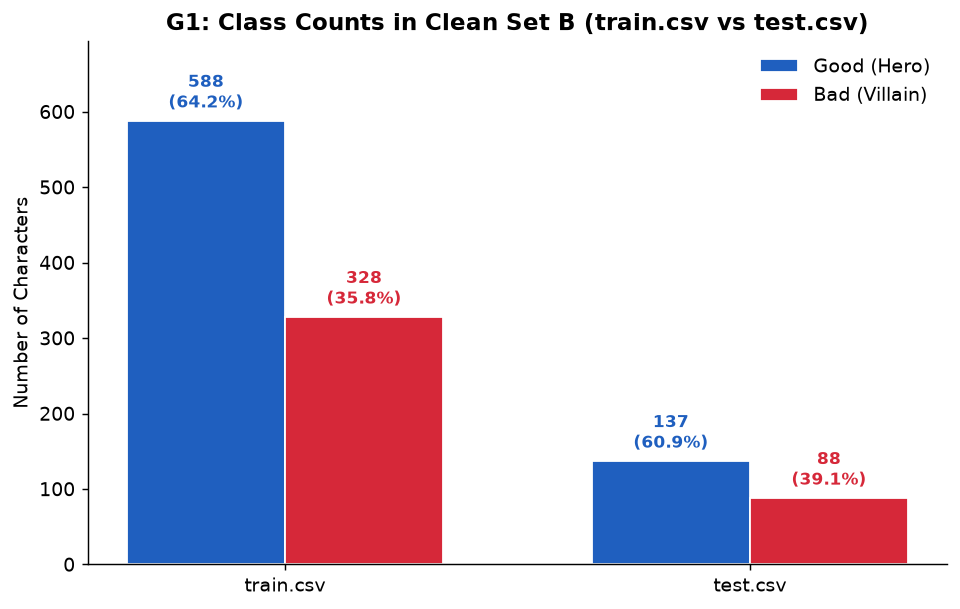

In [5]:
# Graph G1: Class Counts
fig, ax = plt.subplots(figsize=(7.5, 4.8))
splits = ["train.csv", "test.csv"]
x = np.arange(len(splits))
width = 0.34

good_counts = [int((y_train_B == 0).sum()), int((y_test_B == 0).sum())]
bad_counts = [int((y_train_B == 1).sum()), int((y_test_B == 1).sum())]
good_pcts = [100 * good_counts[0] / len(y_train_B), 100 * good_counts[1] / len(y_test_B)]
bad_pcts = [100 * bad_counts[0] / len(y_train_B), 100 * bad_counts[1] / len(y_test_B)]

b1 = ax.bar(x - width / 2, good_counts, width, label="Good (Hero)", color=COLORS["Hero"], edgecolor="white")
b2 = ax.bar(x + width / 2, bad_counts, width, label="Bad (Villain)", color=COLORS["Villain"], edgecolor="white")

for rect, cnt, pct in zip(b1, good_counts, good_pcts):
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 10, f"{cnt}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=COLORS["Hero"])
for rect, cnt, pct in zip(b2, bad_counts, bad_pcts):
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 10, f"{cnt}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=COLORS["Villain"])

ax.set_title("G1: Class Counts in Clean Set B (train.csv vs test.csv)")
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.set_ylabel("Number of Characters")
ax.set_ylim(0, max(good_counts) * 1.18)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "G1.png", bbox_inches="tight")
plt.show()

**Graph G1 Caption:** G1 compares Good (Hero) and Bad (Villain) character counts side by side across `train.csv` (588 vs. 328) and `test.csv` (137 vs. 88). Heroes outnumber Villains in both splits (64.2% and 60.9%), meaning a naive majority-class classifier achieves ~61% test accuracy while completely failing to detect Villains.

In [6]:
# Task 1 Pipelines & 5-Fold Stratified GridSearchCV (train.csv only, n_jobs=1 for clean execution)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Baseline: plain DummyClassifier, no pipeline (it ignores the input values)
baseline_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline_model.fit(X_train_B, y_train_B)

dt_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("clf", DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)),
])
dt_param_grid = {
    "clf__max_depth": [3, 5, 7, 10, None],
    "clf__min_samples_leaf": [1, 5, 10],
}
dt_grid = GridSearchCV(
    dt_pipe,
    dt_param_grid,
    cv=cv_strat,
    scoring="f1_macro",
    refit=True,
    n_jobs=1,
)
dt_grid.fit(X_train_B, y_train_B)

knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(metric="euclidean")),
])
knn_param_grid = {
    "clf__n_neighbors": [3, 5, 7, 9, 11, 15],
    "clf__weights": ["uniform", "distance"],
}
knn_grid = GridSearchCV(
    knn_pipe,
    knn_param_grid,
    cv=cv_strat,
    scoring="f1_macro",
    refit=True,
    n_jobs=1,
)
knn_grid.fit(X_train_B, y_train_B)

t4_df = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Grid Combinations": 15,
        "Best Hyperparameters": str(dt_grid.best_params_),
        "Best 5-Fold CV Macro-F1": round(float(dt_grid.best_score_), 4),
    },
    {
        "Model": "KNN",
        "Grid Combinations": 12,
        "Best Hyperparameters": str(knn_grid.best_params_),
        "Best 5-Fold CV Macro-F1": round(float(knn_grid.best_score_), 4),
    },
])
display(Markdown("### Table T4: Best Settings and Best 5-Fold CV Macro-F1"))
display(t4_df)

### Table T4: Best Settings and Best 5-Fold CV Macro-F1

,Model,Grid Combinations,Best Hyperparameters,Best 5-Fold CV Macro-F1
0,Decision Tree,15,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.5405
1,KNN,12,"{'clf__n_neighbors': 9, 'clf__weights': 'unifo...",0.5145


**Table T4 Caption:** Table T4 reports the 5-fold stratified `GridSearchCV` results on `train.csv` alone: Decision Tree selected `max_depth=5, min_samples_leaf=10` (CV Macro-F1 = 0.5405 across 15 combinations), while KNN selected `n_neighbors=9, weights='uniform'` (CV Macro-F1 = 0.5145 across 12 combinations). Although Decision Tree scored higher in cross-validation, both CV scores remain near 0.51–0.54, foreshadowing limited separability in the 6 numeric scores.

In [7]:
# Single final test evaluation on test.csv
task1_models = {
    "Baseline": baseline_model,
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_grid.best_estimator_,
}

t5_rows = []
t1_test_preds = {}
t1_reports = {}
t1_train_f1_raw = {}
t1_test_f1_raw = {}

for name, est in task1_models.items():
    y_tr_pred = est.predict(X_train_B)
    train_macro_f1 = f1_score(y_train_B, y_tr_pred, average="macro", zero_division=0)
    t1_train_f1_raw[name] = float(train_macro_f1)

    y_te_pred = est.predict(X_test_B)
    t1_test_preds[name] = y_te_pred

    rep_text = classification_report(
        y_test_B, y_te_pred,
        target_names=["Good (Hero)", "Bad (Villain)"],
        digits=3, zero_division=0,
    )
    rep = classification_report(
        y_test_B, y_te_pred,
        target_names=["Good (Hero)", "Bad (Villain)"],
        output_dict=True, zero_division=0,
    )
    t1_reports[name] = rep
    t1_test_f1_raw[name] = float(rep["macro avg"]["f1-score"])
    print(f"=== {name} — Test Classification Report ===")
    print(rep_text)

    t5_rows.append({
        "Model": name,
        "Train Macro-F1": round(float(train_macro_f1), 3),
        "Accuracy": round(float(rep["accuracy"]), 3),
        "Precision Hero": round(float(rep["Good (Hero)"]["precision"]), 3),
        "Recall Hero": round(float(rep["Good (Hero)"]["recall"]), 3),
        "F1 Hero": round(float(rep["Good (Hero)"]["f1-score"]), 3),
        "Precision Villain": round(float(rep["Bad (Villain)"]["precision"]), 3),
        "Recall Villain": round(float(rep["Bad (Villain)"]["recall"]), 3),
        "F1 Villain": round(float(rep["Bad (Villain)"]["f1-score"]), 3),
        "Macro-F1": round(float(rep["macro avg"]["f1-score"]), 3),
    })

t5_df = pd.DataFrame(t5_rows)
display(Markdown("### Table T5: Task 1 Results (Train Macro-F1 & Test Evaluation)"))
display(t5_df)
for name in ["Decision Tree", "KNN"]:
    gap = t1_train_f1_raw[name] - t1_test_f1_raw[name]
    print(f"{name} exact Train - Test Macro-F1 gap = {t1_train_f1_raw[name]:.4f} - {t1_test_f1_raw[name]:.4f} = {gap:.4f} (overfits > 0.10? {gap > 0.10})")

=== Baseline — Test Classification Report ===
               precision    recall  f1-score   support

  Good (Hero)      0.609     1.000     0.757       137
Bad (Villain)      0.000     0.000     0.000        88

     accuracy                          0.609       225
    macro avg      0.304     0.500     0.378       225
 weighted avg      0.371     0.609     0.461       225

=== Decision Tree — Test Classification Report ===
               precision    recall  f1-score   support

  Good (Hero)      0.594     0.876     0.708       137
Bad (Villain)      0.261     0.068     0.108        88

     accuracy                          0.560       225
    macro avg      0.427     0.472     0.408       225
 weighted avg      0.464     0.560     0.473       225



=== KNN — Test Classification Report ===
               precision    recall  f1-score   support

  Good (Hero)      0.624     0.847     0.718       137
Bad (Villain)      0.462     0.205     0.283        88

     accuracy                          0.596       225
    macro avg      0.543     0.526     0.501       225
 weighted avg      0.560     0.596     0.548       225



### Table T5: Task 1 Results (Train Macro-F1 & Test Evaluation)

,Model,Train Macro-F1,Accuracy,Precision Hero,Recall Hero,F1 Hero,Precision Villain,Recall Villain,F1 Villain,Macro-F1
0,Baseline,0.391,0.609,0.609,1.000,0.757,0.000,0.000,0.000,0.378
1,Decision Tree,0.563,0.560,0.594,0.876,0.708,0.261,0.068,0.108,0.408
2,KNN,0.601,0.596,0.624,0.847,0.718,0.462,0.205,0.283,0.501


Decision Tree exact Train - Test Macro-F1 gap = 0.5628 - 0.4080 = 0.1548 (overfits > 0.10? True)
KNN exact Train - Test Macro-F1 gap = 0.6011 - 0.5009 = 0.1003 (overfits > 0.10? True)


**Table T5 Caption:** Table T5 compares Baseline, Decision Tree, and KNN on the held-out `test.csv` set, showing KNN achieves the highest Test Macro-F1 (0.501) and Villain recall (0.205), ahead of Decision Tree (0.408 Macro-F1, 0.068 Villain recall) and Baseline (0.378 Macro-F1, 0.000 Villain recall). By the `Train − Test Macro-F1 > 0.10` rule both models overfit: Decision Tree drops by 0.155 (0.563 → 0.408) and KNN by 0.1003 (0.601 → 0.501), so KNN only just crosses the threshold.

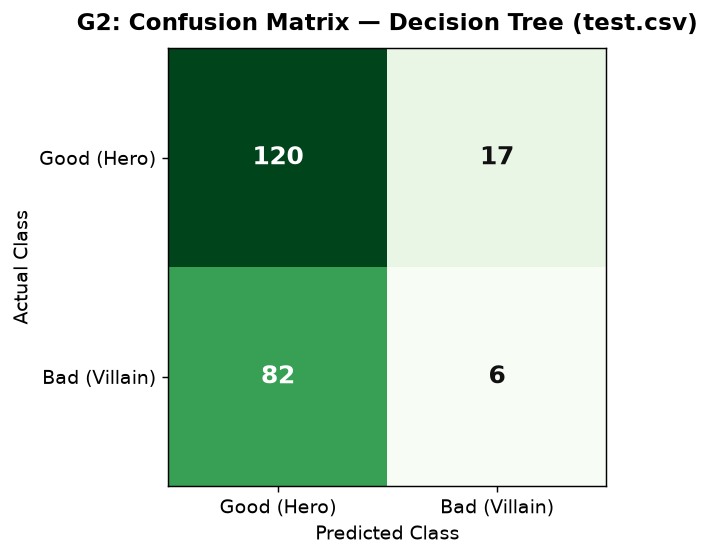

In [8]:
# Graph G2: Confusion Matrix — Decision Tree
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm_dt = plot_cm(ax, y_test_B, t1_test_preds["Decision Tree"],
                "G2: Confusion Matrix — Decision Tree (test.csv)", cmap="Greens")
plt.tight_layout()
plt.savefig(FIG_DIR / "G2.png", bbox_inches="tight")
plt.show()

**Graph G2 Caption:** G2 shows the Decision Tree confusion matrix on `test.csv`, with 120 True Heroes, 17 False Villains, 82 missed Villains (False Heroes), and only 6 True Villains. Because 82 of 88 actual Villains (93.2%) are predicted as Heroes, the tree effectively collapses toward the majority Hero class.

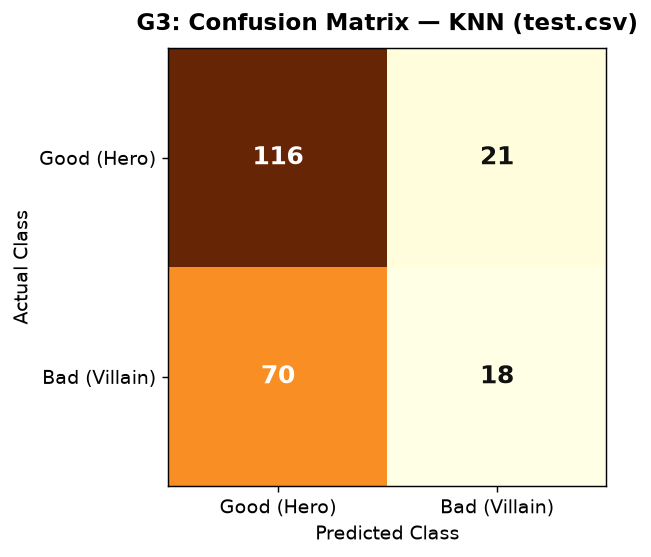

In [9]:
# Graph G3: Confusion Matrix — KNN
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm_knn = plot_cm(ax, y_test_B, t1_test_preds["KNN"],
                 "G3: Confusion Matrix — KNN (test.csv)", cmap="YlOrBr")
plt.tight_layout()
plt.savefig(FIG_DIR / "G3.png", bbox_inches="tight")
plt.show()

**Graph G3 Caption:** G3 shows the KNN confusion matrix on `test.csv`, achieving 116 True Heroes, 21 False Villains, 70 missed Villains, and 18 True Villains. KNN identifies three times as many Villains as the Decision Tree (18 vs. 6, raising Villain recall from 0.068 to 0.205) with only 4 additional Hero false positives.

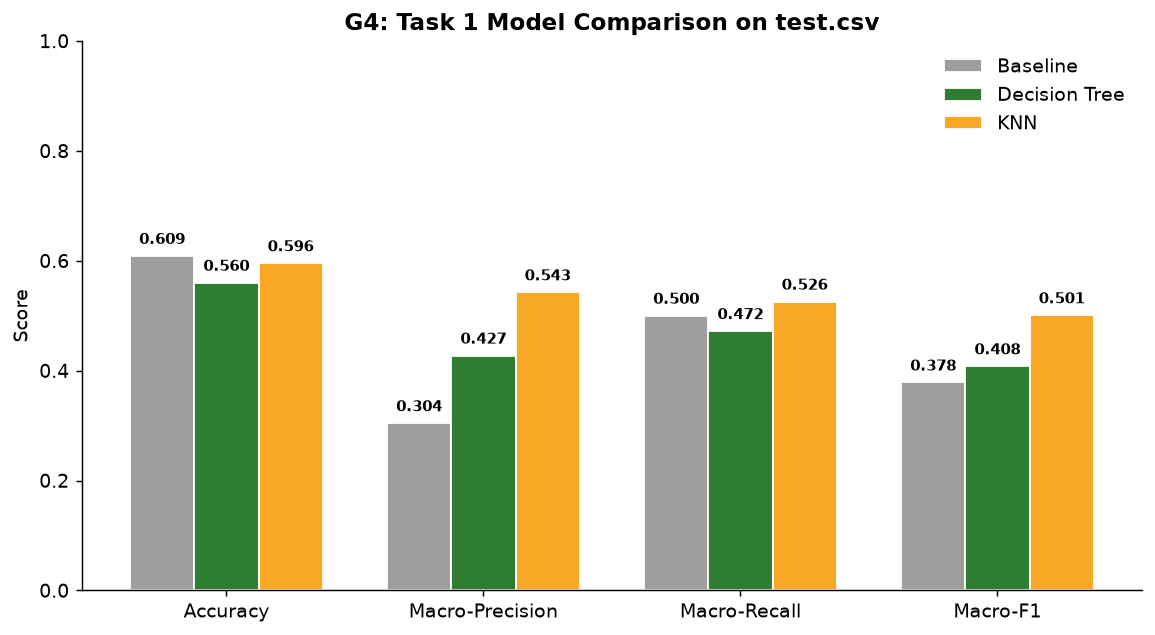

In [10]:
# Graph G4: Model Comparison
metric_names = ["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]
x = np.arange(len(metric_names))
width = 0.25

fig, ax = plt.subplots(figsize=(9.0, 5.0))
for idx, name in enumerate(["Baseline", "Decision Tree", "KNN"]):
    rep = t1_reports[name]
    vals = [
        rep["accuracy"],
        rep["macro avg"]["precision"],
        rep["macro avg"]["recall"],
        rep["macro avg"]["f1-score"],
    ]
    bars = ax.bar(x + (idx - 1) * width, vals, width, label=name, color=COLORS[name], edgecolor="white")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{v:.3f}",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_title("G4: Task 1 Model Comparison on test.csv")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "G4.png", bbox_inches="tight")
plt.show()

**Graph G4 Caption:** G4 compares Accuracy, Macro-Precision, Macro-Recall, and Macro-F1 across the three Task 1 models on `test.csv`. Although Baseline leads slightly on raw Accuracy (0.609) by predicting every character as Hero, KNN dominates all balanced metrics (0.543 Macro-Precision, 0.526 Macro-Recall, and 0.501 Macro-F1).

### Task 1 Report Answers (Q1–Q4)
- **Q1 (Which model wins by the rules?):** **KNN** wins cleanly with the highest test Macro-F1 of **0.501**, beating Decision Tree (**0.408**) by **0.093** (exceeding the `< 0.01` tie-break threshold) and Baseline (**0.378**) by **0.123**; KNN also leads on Villain recall (**0.205** vs. **0.068** and **0.000**).
- **Q2 (Did both models beat the Baseline? By how much?):** **Yes** on the primary Macro-F1 metric: KNN beats Baseline (**0.378**) by **+0.123** (0.501), and Decision Tree beats Baseline by **+0.030** (0.408). (On raw accuracy alone, neither beat Baseline's 0.609 because Baseline predicts Hero for every test character.)
- **Q3 (Which class is harder to predict?):** **Bad (Villain)** is substantially harder to predict. In `G2` (Decision Tree), only **6 / 88** Villains (**6.8%** recall) are detected while **82** are misclassified as Heroes (vs. **120 / 137 = 87.6%** Hero recall). In `G3` (KNN), only **18 / 88** Villains (**20.5%** recall) are detected while **70** are missed (vs. **116 / 137 = 84.7%** Hero recall).
- **Q4 (Does either model overfit?):** Under the `Train Macro-F1 − Test Macro-F1 > 0.10` rule, **Decision Tree clearly overfits** with a gap of **0.155** (`0.563 − 0.408 = 0.155`, unrounded `0.5628 − 0.4080 = 0.1548 > 0.10`). **KNN sits right at the 0.10 boundary**: `0.601 − 0.501 = 0.100` at 3 decimals, and `0.6011 − 0.5009 = 0.1003` unrounded—technically marginal overfitting (`> 0.10` by `0.0003`), though substantially more stable than the Decision Tree.

---
## Section 4: Task 2 — Unsupervised Clustering (K-Means & Agglomerative Ward) (25 Marks)
Using **Clean Set A** (`train.csv` only, 1,072 characters, strictly 6 numeric ability scores, zero labels, `test.csv` never touched).

,k,Inertia,Silhouette Score
0,2,4154.07,0.3070
1,3,3525.90,0.2374
2,4,3041.33,0.2397
3,5,2727.54,0.2284
4,6,2539.60,0.2217
5,7,2383.11,0.2222
6,8,2253.91,0.2214


Selected final_k = 2 (highest Silhouette = 0.3070)


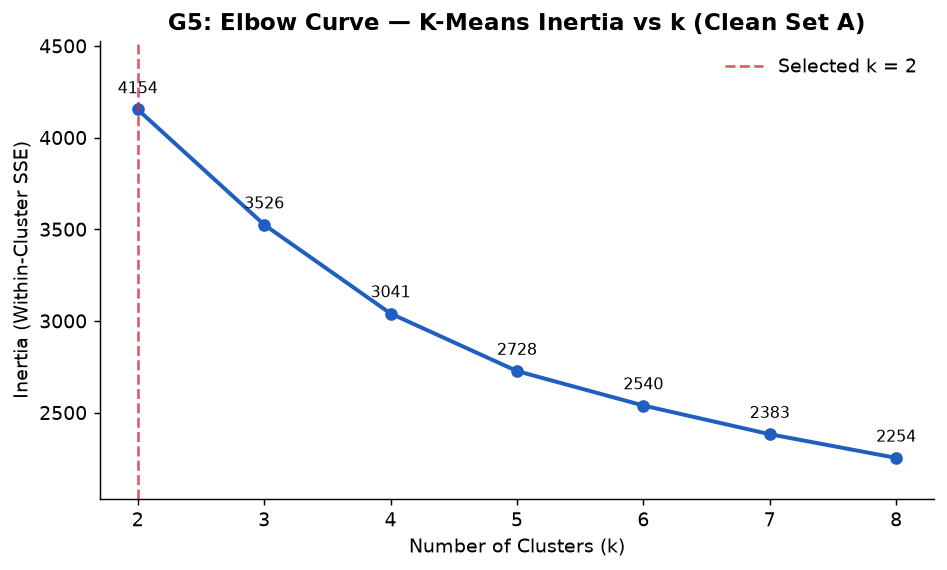

In [11]:
# Fit median imputer + StandardScaler on Clean Set A (6 scores only)
X_A_raw = clean_set_A[FEATURE_COLS].copy()
imputer_A = SimpleImputer(strategy="median")
scaler_A = StandardScaler()

X_A_imp = imputer_A.fit_transform(X_A_raw)
X_A_scaled = scaler_A.fit_transform(X_A_imp)

# K-Means for k = 2..8
k_values = list(range(2, 9))
inertias = []
sil_scores = []
km_models = {}

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_A_scaled)
    inertias.append(float(km.inertia_))
    sil_scores.append(float(silhouette_score(X_A_scaled, labels)))
    km_models[k] = (km, labels)

rounded_sils = [round(s, 3) for s in sil_scores]
max_sil_rounded = max(rounded_sils)
final_k = k_values[rounded_sils.index(max_sil_rounded)]

k_search_df = pd.DataFrame({
    "k": k_values,
    "Inertia": [round(v, 2) for v in inertias],
    "Silhouette Score": [round(s, 4) for s in sil_scores],
})
display(k_search_df)
print(f"Selected final_k = {final_k} (highest Silhouette = {sil_scores[k_values.index(final_k)]:.4f})")

# Graph G5: Elbow Curve (with top/bottom padding so labels never clip)
fig, ax = plt.subplots(figsize=(7.4, 4.5))
ax.plot(k_values, inertias, marker="o", linewidth=2.2, color="#1F5FBF")
ax.axvline(final_k, linestyle="--", color="#D62839", alpha=0.75, label=f"Selected k = {final_k}")
for k, ine in zip(k_values, inertias):
    ax.annotate(f"{ine:.0f}", (k, ine), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.8)
ax.set_title("G5: Elbow Curve — K-Means Inertia vs k (Clean Set A)")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Inertia (Within-Cluster SSE)")
ax.set_xticks(k_values)
ax.set_ylim(min(inertias) * 0.90, max(inertias) * 1.09)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "G5.png", bbox_inches="tight")
plt.show()

**Graph G5 Caption:** G5 plots K-Means inertia across `k = 2..8` on scaled Clean Set A, dropping from 4,154 at `k = 2` to 3,526 at `k = 3` (−628) and 3,041 at `k = 4` (−485) before flattening more gradually from `k = 5` to `k = 8`. While the Elbow curve suggests a mild bend around `k = 4`, the Silhouette rule strictly selects `k = 2`.

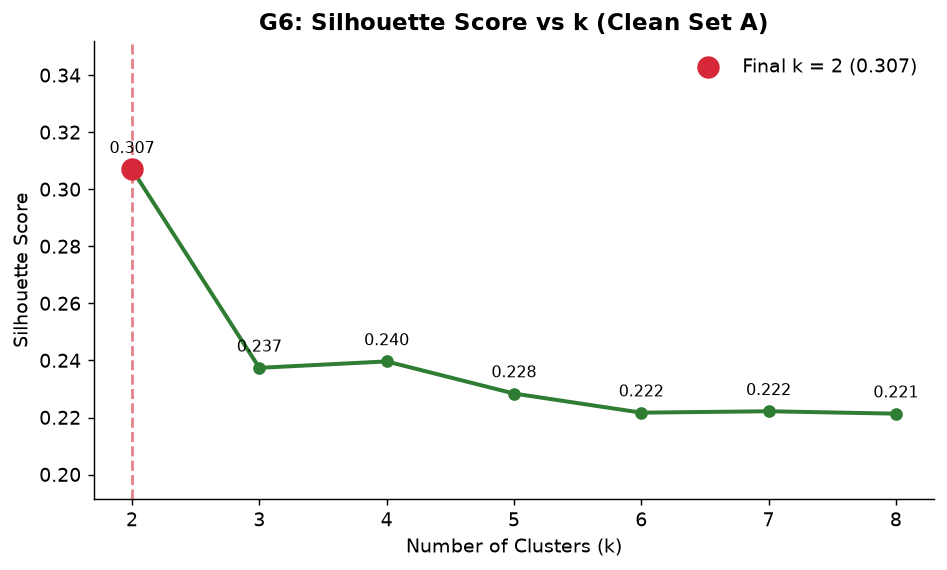

In [12]:
# Graph G6: Silhouette Score vs k
fig, ax = plt.subplots(figsize=(7.4, 4.5))
ax.plot(k_values, sil_scores, marker="o", linewidth=2.2, color="#2E7D32")
best_idx = k_values.index(final_k)
ax.scatter([final_k], [sil_scores[best_idx]], s=130, color="#D62839", zorder=5, label=f"Final k = {final_k} ({sil_scores[best_idx]:.3f})")
ax.axvline(final_k, linestyle="--", color="#D62839", alpha=0.6)
for k, s in zip(k_values, sil_scores):
    ax.annotate(f"{s:.3f}", (k, s), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.8)
ax.set_title("G6: Silhouette Score vs k (Clean Set A)")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(k_values)
ax.set_ylim(min(sil_scores) - 0.03, max(sil_scores) + 0.045)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "G6.png", bbox_inches="tight")
plt.show()

**Graph G6 Caption:** G6 shows K-Means Silhouette scores across `k = 2..8`, peaking clearly at `k = 2` (0.307) before falling to 0.237–0.240 at `k = 3–4` and ~0.221–0.228 for `k = 5–8`. Because 0.307 lies in the 0.26–0.50 band, `k = 2` is selected as the strongest configuration, representing a weak but real two-group structure.

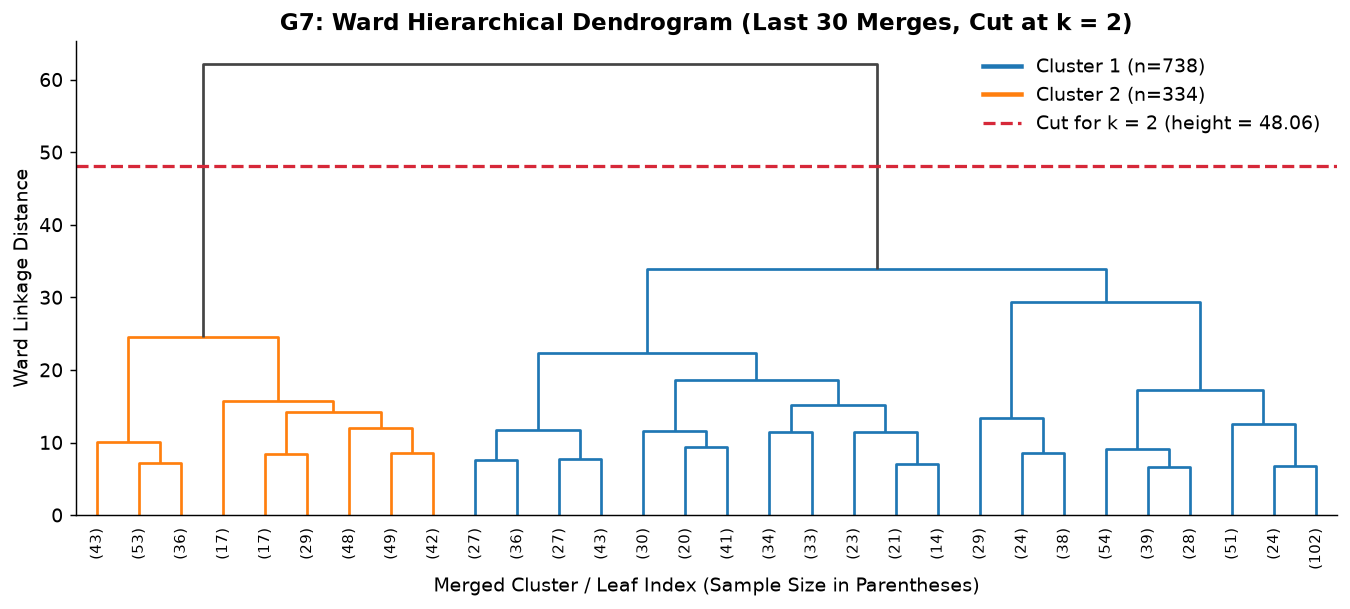

In [13]:
# Agglomerative Clustering (Ward) & Dendrogram (G7)
from matplotlib.colors import to_hex
from matplotlib.lines import Line2D

_, km_labels_raw = km_models[final_k]
agg_model = AgglomerativeClustering(n_clusters=final_k, linkage="ward")
agg_labels_raw = agg_model.fit_predict(X_A_scaled)

# Step 7: Renumber clusters ascending by original 0-100 scale mean (lowest = Cluster 1).
# Done here so that G7 already follows the "Cluster c = tab10 colour c" rule.
X_A_imp_df = pd.DataFrame(X_A_imp, columns=FEATURE_COLS)

def renumber_clusters(raw_labels, df_0_100):
    temp = df_0_100.copy()
    temp["raw"] = raw_labels
    overall_means = temp.groupby("raw")[FEATURE_COLS].mean().mean(axis=1).sort_values(ascending=True)
    mapping = {old_lbl: new_idx + 1 for new_idx, old_lbl in enumerate(overall_means.index)}
    return np.array([mapping[l] for l in raw_labels]), mapping

km_clusters, km_map = renumber_clusters(km_labels_raw, X_A_imp_df)
agg_clusters, agg_map = renumber_clusters(agg_labels_raw, X_A_imp_df)

Z = linkage(X_A_scaled, method="ward")
cut_height = float((Z[-(final_k - 1), 2] + Z[-final_k, 2]) / 2.0)

# Colour every link below the cut by the (renumbered) Ward cluster of its leaves; links above the cut in dark grey
n_leaves = X_A_scaled.shape[0]
node_leaf = list(range(n_leaves))  # one representative leaf per tree node
for left, right, _, _ in Z:
    node_leaf.append(node_leaf[int(left)])

def link_color(node_id):
    if Z[node_id - n_leaves, 2] > cut_height:
        return "#444444"
    return to_hex(TAB10[agg_clusters[node_leaf[node_id]] - 1])

fig, ax = plt.subplots(figsize=(10.5, 4.8))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=8.5, link_color_func=link_color)
cut_line = ax.axhline(y=cut_height, color="#D62839", linestyle="--", linewidth=1.8, label=f"Cut for k = {final_k} (height = {cut_height:.2f})")
cluster_handles = [
    Line2D([0], [0], color=TAB10[c - 1], linewidth=2.5, label=f"Cluster {c} (n={int((agg_clusters == c).sum())})")
    for c in range(1, final_k + 1)
]
ax.set_title(f"G7: Ward Hierarchical Dendrogram (Last 30 Merges, Cut at k = {final_k})")
ax.set_xlabel("Merged Cluster / Leaf Index (Sample Size in Parentheses)")
ax.set_ylabel("Ward Linkage Distance")
ax.legend(handles=cluster_handles + [cut_line], frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "G7.png", bbox_inches="tight")
plt.show()

**Graph G7 Caption:** G7 displays the truncated Ward hierarchical dendrogram (last 30 merges) with a horizontal dashed cut at linkage height 48.06, splitting the characters into Cluster 1 (blue, n = 738) and Cluster 2 (orange, n = 334) in the same tab10 colours as G9 and G11. The wide vertical gap between the two-cluster level (33.9) and the root merge (~62.3) visually corroborates `k = 2` as the most natural Ward split.

In [14]:
# Unsupervised Metrics on Scaled Data & Table T6
def eval_clustering(X_scaled, labels):
    return {
        "Silhouette": float(silhouette_score(X_scaled, labels)),
        "Davies-Bouldin": float(davies_bouldin_score(X_scaled, labels)),
        "Calinski-Harabasz": float(calinski_harabasz_score(X_scaled, labels)),
    }

m_km = eval_clustering(X_A_scaled, km_labels_raw)
m_agg = eval_clustering(X_A_scaled, agg_labels_raw)
ari_val = float(adjusted_rand_score(km_labels_raw, agg_labels_raw))

km_wins = (
    int(m_km["Silhouette"] > m_agg["Silhouette"])
    + int(m_km["Davies-Bouldin"] < m_agg["Davies-Bouldin"])
    + int(m_km["Calinski-Harabasz"] > m_agg["Calinski-Harabasz"])
)
agg_wins = 3 - km_wins

t6_df = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "k": final_k,
        "Silhouette ↑": round(m_km["Silhouette"], 4),
        "Davies–Bouldin ↓": round(m_km["Davies-Bouldin"], 4),
        "Calinski–Harabasz ↑": round(m_km["Calinski-Harabasz"], 2),
        "Wins (of 3)": km_wins,
    },
    {
        "Algorithm": "Agglomerative (Ward)",
        "k": final_k,
        "Silhouette ↑": round(m_agg["Silhouette"], 4),
        "Davies–Bouldin ↓": round(m_agg["Davies-Bouldin"], 4),
        "Calinski–Harabasz ↑": round(m_agg["Calinski-Harabasz"], 2),
        "Wins (of 3)": agg_wins,
    },
    {
        "Algorithm": "ARI between the two",
        "k": final_k,
        "Silhouette ↑": f"ARI = {ari_val:.4f}",
        "Davies–Bouldin ↓": "—",
        "Calinski–Harabasz ↑": "—",
        "Wins (of 3)": "—",
    },
])
display(Markdown("### Table T6: Clustering Metrics & ARI"))
display(t6_df)

### Table T6: Clustering Metrics & ARI

,Algorithm,k,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,Wins (of 3)
0,K-Means,2,0.307,1.274,586.75,3
1,Agglomerative (Ward),2,0.2779,1.2898,460.92,0
2,ARI between the two,2,ARI = 0.4834,—,—,—


**Table T6 Caption:** Table T6 shows that K-Means wins all 3 internal separation metrics on scaled Clean Set A (Silhouette 0.3070 vs. 0.2779, Davies–Bouldin 1.2740 vs. 1.2898, and Calinski–Harabasz 586.75 vs. 460.92). The Adjusted Rand Index between K-Means and Agglomerative Ward is 0.4834, falling in the moderate agreement band (0.40–0.69).

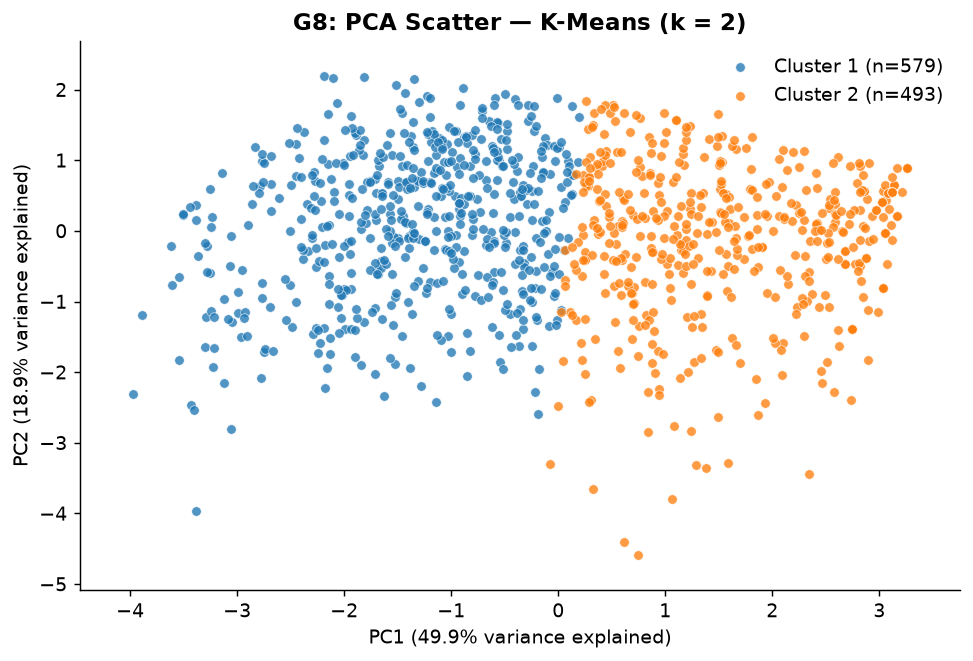

In [15]:
# (Clusters were already renumbered in the G7 cell: lowest average = Cluster 1)

# Fit PCA(n_components=2, random_state=42) ONCE for both G8 and G9
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_A_pca = pca.fit_transform(X_A_scaled)
var_exp = pca.explained_variance_ratio_ * 100
xlim = (X_A_pca[:, 0].min() - 0.5, X_A_pca[:, 0].max() + 0.5)
ylim = (X_A_pca[:, 1].min() - 0.5, X_A_pca[:, 1].max() + 0.5)

def plot_pca_clusters(clusters, title, filename):
    fig, ax = plt.subplots(figsize=(7.6, 5.2))
    for c in sorted(np.unique(clusters)):
        mask = clusters == c
        ax.scatter(
            X_A_pca[mask, 0], X_A_pca[mask, 1],
            s=28, alpha=0.78, color=TAB10[c - 1],
            label=f"Cluster {c} (n={mask.sum()})", edgecolors="white", linewidths=0.4,
        )
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance explained)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance explained)")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.legend(frameon=False, loc="best")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()

plot_pca_clusters(km_clusters, f"G8: PCA Scatter — K-Means (k = {final_k})", "G8.png")

**Graph G8 Caption:** G8 projects the K-Means clusters onto the first two principal components (capturing 68.8% of total variance: 49.9% on PC1 and 18.9% on PC2). K-Means splits characters cleanly near `PC1 ≈ 0` into Cluster 1 (n = 579, lower overall scores) and Cluster 2 (n = 493, higher overall scores).

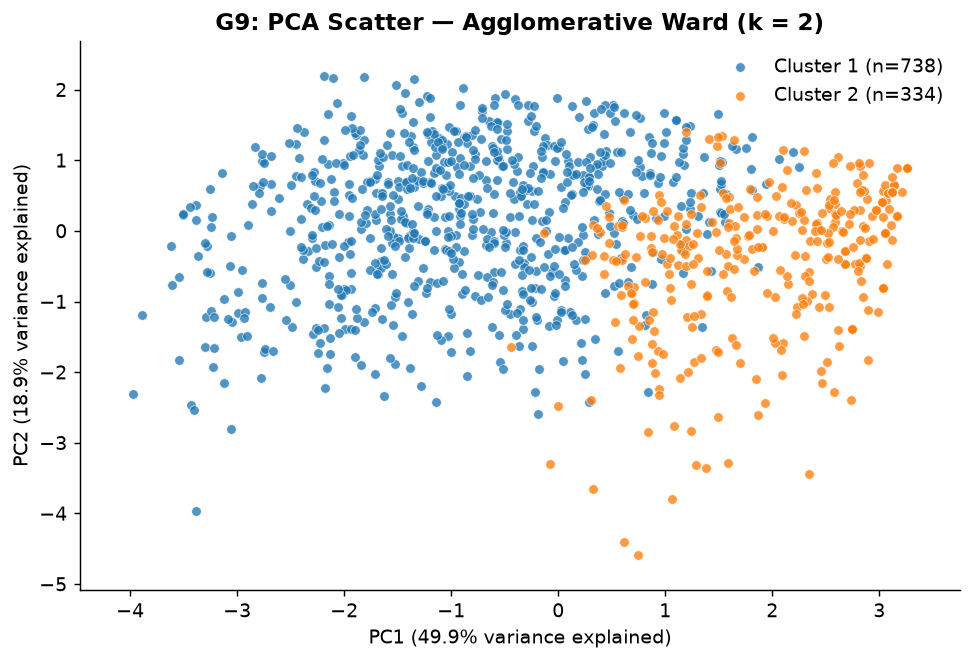

In [16]:
plot_pca_clusters(agg_clusters, f"G9: PCA Scatter — Agglomerative Ward (k = {final_k})", "G9.png")

**Graph G9 Caption:** G9 shows the Agglomerative Ward clusters on the exact same 2D PCA axes as G8 (`PC1 = 49.9%`, `PC2 = 18.9%`). Compared with K-Means, Ward shifts the boundary rightward to `PC1 ≈ 0.8–1.0`, yielding a larger Cluster 1 (n = 738) and a tighter, higher-scoring Cluster 2 (n = 334) with mild boundary overlap in 2D PCA space.

In [17]:
# Cluster profiles & Table T7 (both algorithms, with exact 'Name you give' column)
KM_NAMES = {
    1: "Tacticians & Street-Level Fighters",
    2: "Cosmic & Superhuman Powerhouses",
}
AGG_NAMES = {
    1: "Skilled Tacticians & Mid-Tier Powered",
    2: "Apex Super-Strength Powerhouses",
}

def build_profile_table(clusters, df_0_100, name_map):
    temp = df_0_100.copy()
    temp["Cluster"] = clusters
    rows = []
    for c in sorted(temp["Cluster"].unique()):
        sub = temp[temp["Cluster"] == c]
        means = sub[FEATURE_COLS].mean()
        rows.append({
            "Cluster": f"Cluster {c}",
            "Size": int(len(sub)),
            "INT": round(float(means["intelligence_score"]), 1),
            "STR": round(float(means["strength_score"]), 1),
            "SPD": round(float(means["speed_score"]), 1),
            "DUR": round(float(means["durability_score"]), 1),
            "POW": round(float(means["power_score"]), 1),
            "COM": round(float(means["combat_score"]), 1),
            "Name you give": name_map[c],
        })
    return pd.DataFrame(rows)

t7_km = build_profile_table(km_clusters, X_A_imp_df, KM_NAMES)
t7_agg = build_profile_table(agg_clusters, X_A_imp_df, AGG_NAMES)

# Q7 "easier to interpret": how far apart the cluster profiles are (sum over the 6 scores of max - min cluster mean)
profile_spread = {
    "K-Means": (t7_km[SHORT_LABELS].max() - t7_km[SHORT_LABELS].min()),
    "Agglomerative (Ward)": (t7_agg[SHORT_LABELS].max() - t7_agg[SHORT_LABELS].min()),
}

display(Markdown("### Table T7a: K-Means Cluster Profiles (Original 0–100 Scale)"))
display(t7_km)
display(Markdown("### Table T7b: Agglomerative (Ward) Cluster Profiles (Original 0–100 Scale)"))
display(t7_agg)
spread_df = pd.DataFrame(profile_spread).T.round(1)
spread_df["Total spread"] = spread_df[SHORT_LABELS].sum(axis=1).round(1)
print("Cluster profile spread per score (max - min cluster mean, 0-100 scale):")
print(spread_df.to_string())

### Table T7a: K-Means Cluster Profiles (Original 0–100 Scale)

,Cluster,Size,INT,STR,SPD,DUR,POW,COM,Name you give
0,Cluster 1,579,84.5,20.6,33.1,40.9,54.0,67.4,Tacticians & Street-Level Fighters
1,Cluster 2,493,86.3,69.5,71.1,83.5,93.3,81.6,Cosmic & Superhuman Powerhouses


### Table T7b: Agglomerative (Ward) Cluster Profiles (Original 0–100 Scale)

,Cluster,Size,INT,STR,SPD,DUR,POW,COM,Name you give
0,Cluster 1,738,85.7,24.5,40.1,47.5,61.7,70.2,Skilled Tacticians & Mid-Tier Powered
1,Cluster 2,334,84.5,84.3,73.7,89.1,95.0,82.1,Apex Super-Strength Powerhouses


Cluster profile spread per score (max - min cluster mean, 0-100 scale):
                      INT   STR   SPD   DUR   POW   COM  Total spread
K-Means               1.8  48.9  38.0  42.6  39.3  14.2         184.8
Agglomerative (Ward)  1.2  59.8  33.6  41.6  33.3  11.9         181.4


**Table T7 Caption:** Tables T7a and T7b detail the mean ability scores (0–100 scale) after renumbering clusters ascending by overall mean: in both algorithms, `Cluster 1` captures high-intelligence, lower-strength fighters (K-Means mean 50.1, `STR=20.6`; Ward mean 55.0, `STR=24.5`), while `Cluster 2` groups all-round superhuman powerhouses (K-Means mean 80.9, `POW=93.3`; Ward mean 84.8, `STR=84.3, POW=95.0`).

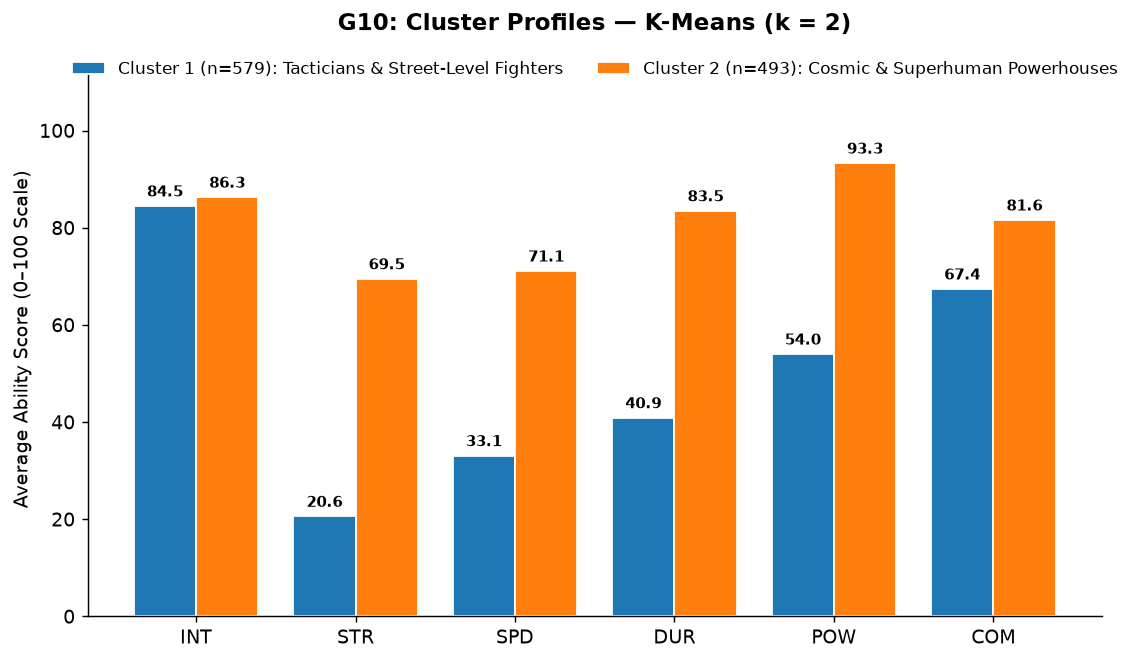

In [18]:
def plot_cluster_profiles(profile_df, title, filename):
    fig, ax = plt.subplots(figsize=(9.2, 5.2))
    n_clusters = len(profile_df)
    x = np.arange(len(SHORT_LABELS))
    width = 0.78 / n_clusters
    for idx, row in profile_df.iterrows():
        vals = [row[s] for s in SHORT_LABELS]
        offset = (idx - (n_clusters - 1) / 2.0) * width
        bars = ax.bar(x + offset, vals, width, label=f"{row['Cluster']} (n={row['Size']}): {row['Name you give']}",
                      color=TAB10[idx], edgecolor="white")
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{v:.1f}",
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax.set_title(title, pad=18)
    ax.set_xticks(x)
    ax.set_xticklabels(SHORT_LABELS)
    ax.set_ylabel("Average Ability Score (0–100 Scale)")
    ax.set_ylim(0, 114)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, fontsize=9.2)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()

plot_cluster_profiles(t7_km, f"G10: Cluster Profiles — K-Means (k = {final_k})", "G10.png")

**Graph G10 Caption:** G10 plots mean ability scores across all 6 dimensions for the K-Means clusters, showing virtually identical intelligence (`84.5` vs. `86.3`) but massive gaps in Strength (`20.6` vs. `69.5`), Durability (`40.9` vs. `83.5`), Power (`54.0` vs. `93.3`), and Speed (`33.1` vs. `71.1`). Thus, K-Means cleanly separates physical/supernatural powerhouses from tactical/street-level characters.

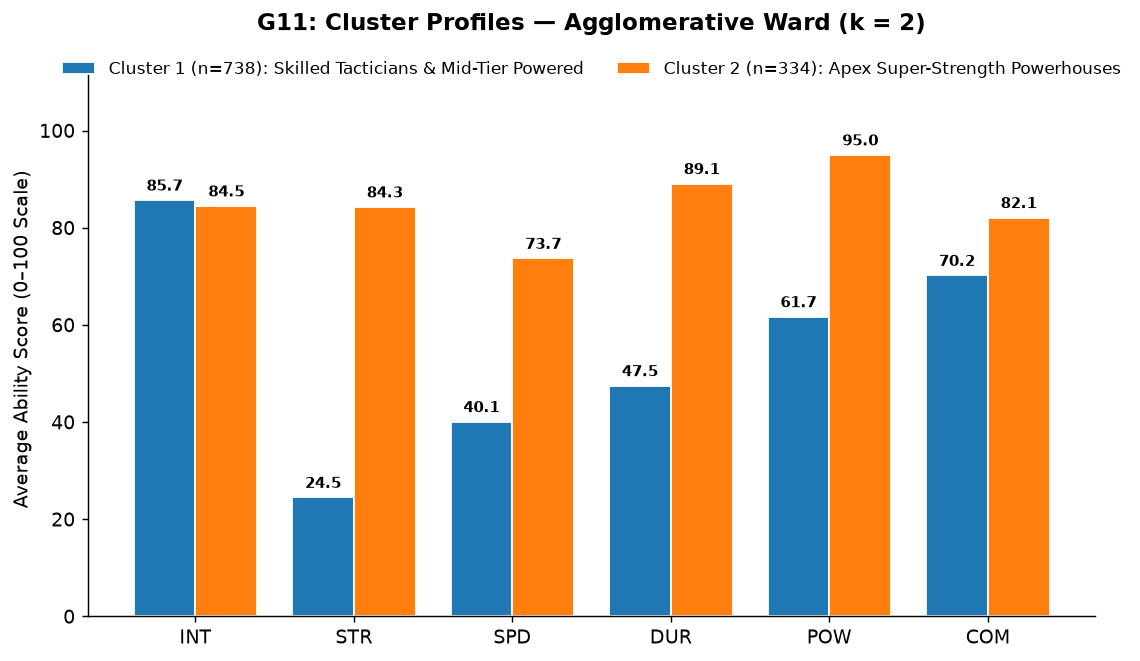

In [19]:
plot_cluster_profiles(t7_agg, f"G11: Cluster Profiles — Agglomerative Ward (k = {final_k})", "G11.png")

**Graph G11 Caption:** G11 plots the Agglomerative Ward cluster profiles, showing the same pattern as K-Means with an even steeper Strength contrast (`24.5` in Cluster 1 vs. `84.3` in Cluster 2) and slightly higher Cluster 2 peaks in Durability (`89.1`) and Power (`95.0`). Both algorithms confirm that physical and energy-power scores—not intelligence—drive unsupervised cluster separation.

In [20]:
# Step 8: Reveal alignment ONLY AFTER clustering is finalized -> Table T8
def alignment_mix_table(clusters, align_series, algo_name):
    df_tmp = pd.DataFrame({"Cluster": clusters, "alignment": align_series.values})
    rows = []
    for c in sorted(df_tmp["Cluster"].unique()):
        sub = df_tmp[df_tmp["Cluster"] == c]
        n = len(sub)
        rows.append({
            "Algorithm": algo_name,
            "Cluster": f"Cluster {c}",
            "Size": n,
            "% Good": round(100 * (sub["alignment"] == "Good").sum() / n, 1),
            "% Bad": round(100 * (sub["alignment"] == "Bad").sum() / n, 1),
            "% Neutral": round(100 * (sub["alignment"] == "Neutral").sum() / n, 1),
            "% blank": round(100 * sub["alignment"].isna().sum() / n, 1),
        })
    return pd.DataFrame(rows)

t8_df = pd.concat([
    alignment_mix_table(km_clusters, align_A_held_aside, "K-Means"),
    alignment_mix_table(agg_clusters, align_A_held_aside, "Agglomerative (Ward)"),
], ignore_index=True)
display(Markdown("### Table T8: Alignment Mix in Each Cluster (%) — Revealed in Step 8"))
display(t8_df)

### Table T8: Alignment Mix in Each Cluster (%) — Revealed in Step 8

,Algorithm,Cluster,Size,% Good,% Bad,% Neutral,% blank
0,K-Means,Cluster 1,579,60.6,27.3,6.4,5.7
1,K-Means,Cluster 2,493,48.1,34.5,11.4,6.1
2,Agglomerative (Ward),Cluster 1,738,59.9,27.4,6.9,5.8
3,Agglomerative (Ward),Cluster 2,334,43.7,37.7,12.6,6.0


**Table T8 Caption:** Table T8 reveals the held-aside `alignment` breakdown inside each finalized cluster: in both K-Means and Ward, `Cluster 1` is ~60% Good and ~27.3–27.4% Bad, whereas the high-power `Cluster 2` holds a larger Bad share (34.5% in K-Means, 37.7% in Ward) and Neutral share (11.4%–12.6%). No cluster is predominantly Villain, confirming why supervised alignment prediction from the 6 scores alone is challenging.

### Task 2 Report Answers (Q5–Q8)
- **Q5 (Which `k` did you choose? What does the Elbow say?):** We chose **`k = 2`** because it achieved the highest Silhouette Score in `k = 2..8` (**0.307**, weak structure band `0.26–0.50`, well above `0.240` at `k = 4` and `0.237` at `k = 3`). The Elbow curve (`G5`) shows steep inertia drops from `k = 2` (4,154) to `k = 3` (3,526) and `k = 4` (3,041) before flattening, hinting at a secondary bend near `k = 4`, but per the locked selection rule the Elbow does not override Silhouette.
- **Q6 (Did the two algorithms find similar groups?):** They found **moderately similar** groupings: **ARI = 0.4834** (moderate agreement band `0.40–0.69`), and both algorithms' profiles (`G10`, `G11`) separate a high-intelligence/low-strength group (`Cluster 1`) from a high-power/high-durability powerhouse group (`Cluster 2`). They differ mainly in threshold placement (`n = 579/493` in K-Means vs. `n = 738/334` in Ward).
- **Q7 (Which grouping is better separated, and which is easier to interpret?):** **K-Means** is better separated because it wins **all 3 of 3** internal metrics (`Silhouette 0.3070 > 0.2779`, `Davies–Bouldin 1.2740 < 1.2898`, `Calinski–Harabasz 586.75 > 460.92`, meeting the `≥ 2 of 3` rule) and splits PCA space cleanly (`G8`). **K-Means** is also easier to interpret: summed over the 6 scores its two cluster profiles (`G10`) differ by **184.8** points vs. **181.4** for Ward (`G11`), with wider gaps on SPD (38.0 vs. 33.6), DUR (42.6 vs. 41.6), POW (39.3 vs. 33.3) and COM (14.2 vs. 11.9). Ward separates more sharply only on Strength (`STR 84.3 vs. 24.5`, a 59.8-point gap vs. 48.9 for K-Means).
- **Q8 (Describe each cluster in plain words. Is any cluster mostly villains?):** **Cluster 1** (*Tacticians & Street-Level Fighters* in K-Means, n = 579; *Skilled Tacticians & Mid-Tier Powered* in Ward, n = 738) represents smart (`INT ~85`), combat-capable (`COM 67–70`) characters with low physical Strength (`20.6–24.5`) and lower Speed/Durability. **Cluster 2** (*Cosmic & Superhuman Powerhouses* in K-Means, n = 493; *Apex Super-Strength Powerhouses* in Ward, n = 334) represents elite all-rounders scoring `~70–95` across every stat, especially Power (`93.3–95.0`) and Durability (`83.5–89.1`). **No cluster is mostly villains**—both clusters have more Heroes than Villains (60.6% and 48.1% Good in K-Means; 59.9% and 43.7% Good in Ward), though Villains are noticeably more concentrated in the powerhouse `Cluster 2` (34.5%–37.7% Bad vs. 27.3%–27.4% in `Cluster 1`).

---
## Section 5: Task 3 — Neural Networks (MLPs) & Final 5-Model Ranking (25 Marks)
Clean Set B `train.csv` is split 80/20 stratified (`random_state=42`); median imputer and `StandardScaler` are fit on the **80% fit split ONLY**. *(Note for final comparison: Decision Tree and KNN trained on 100% of `train.csv`, whereas Networks A and B train on 80%.)*

NN 80% fit shape: (732, 6), 20% val shape: (184, 6), test shape: (225, 6)


### Graph G12: Architecture Diagrams — Network A & Network B

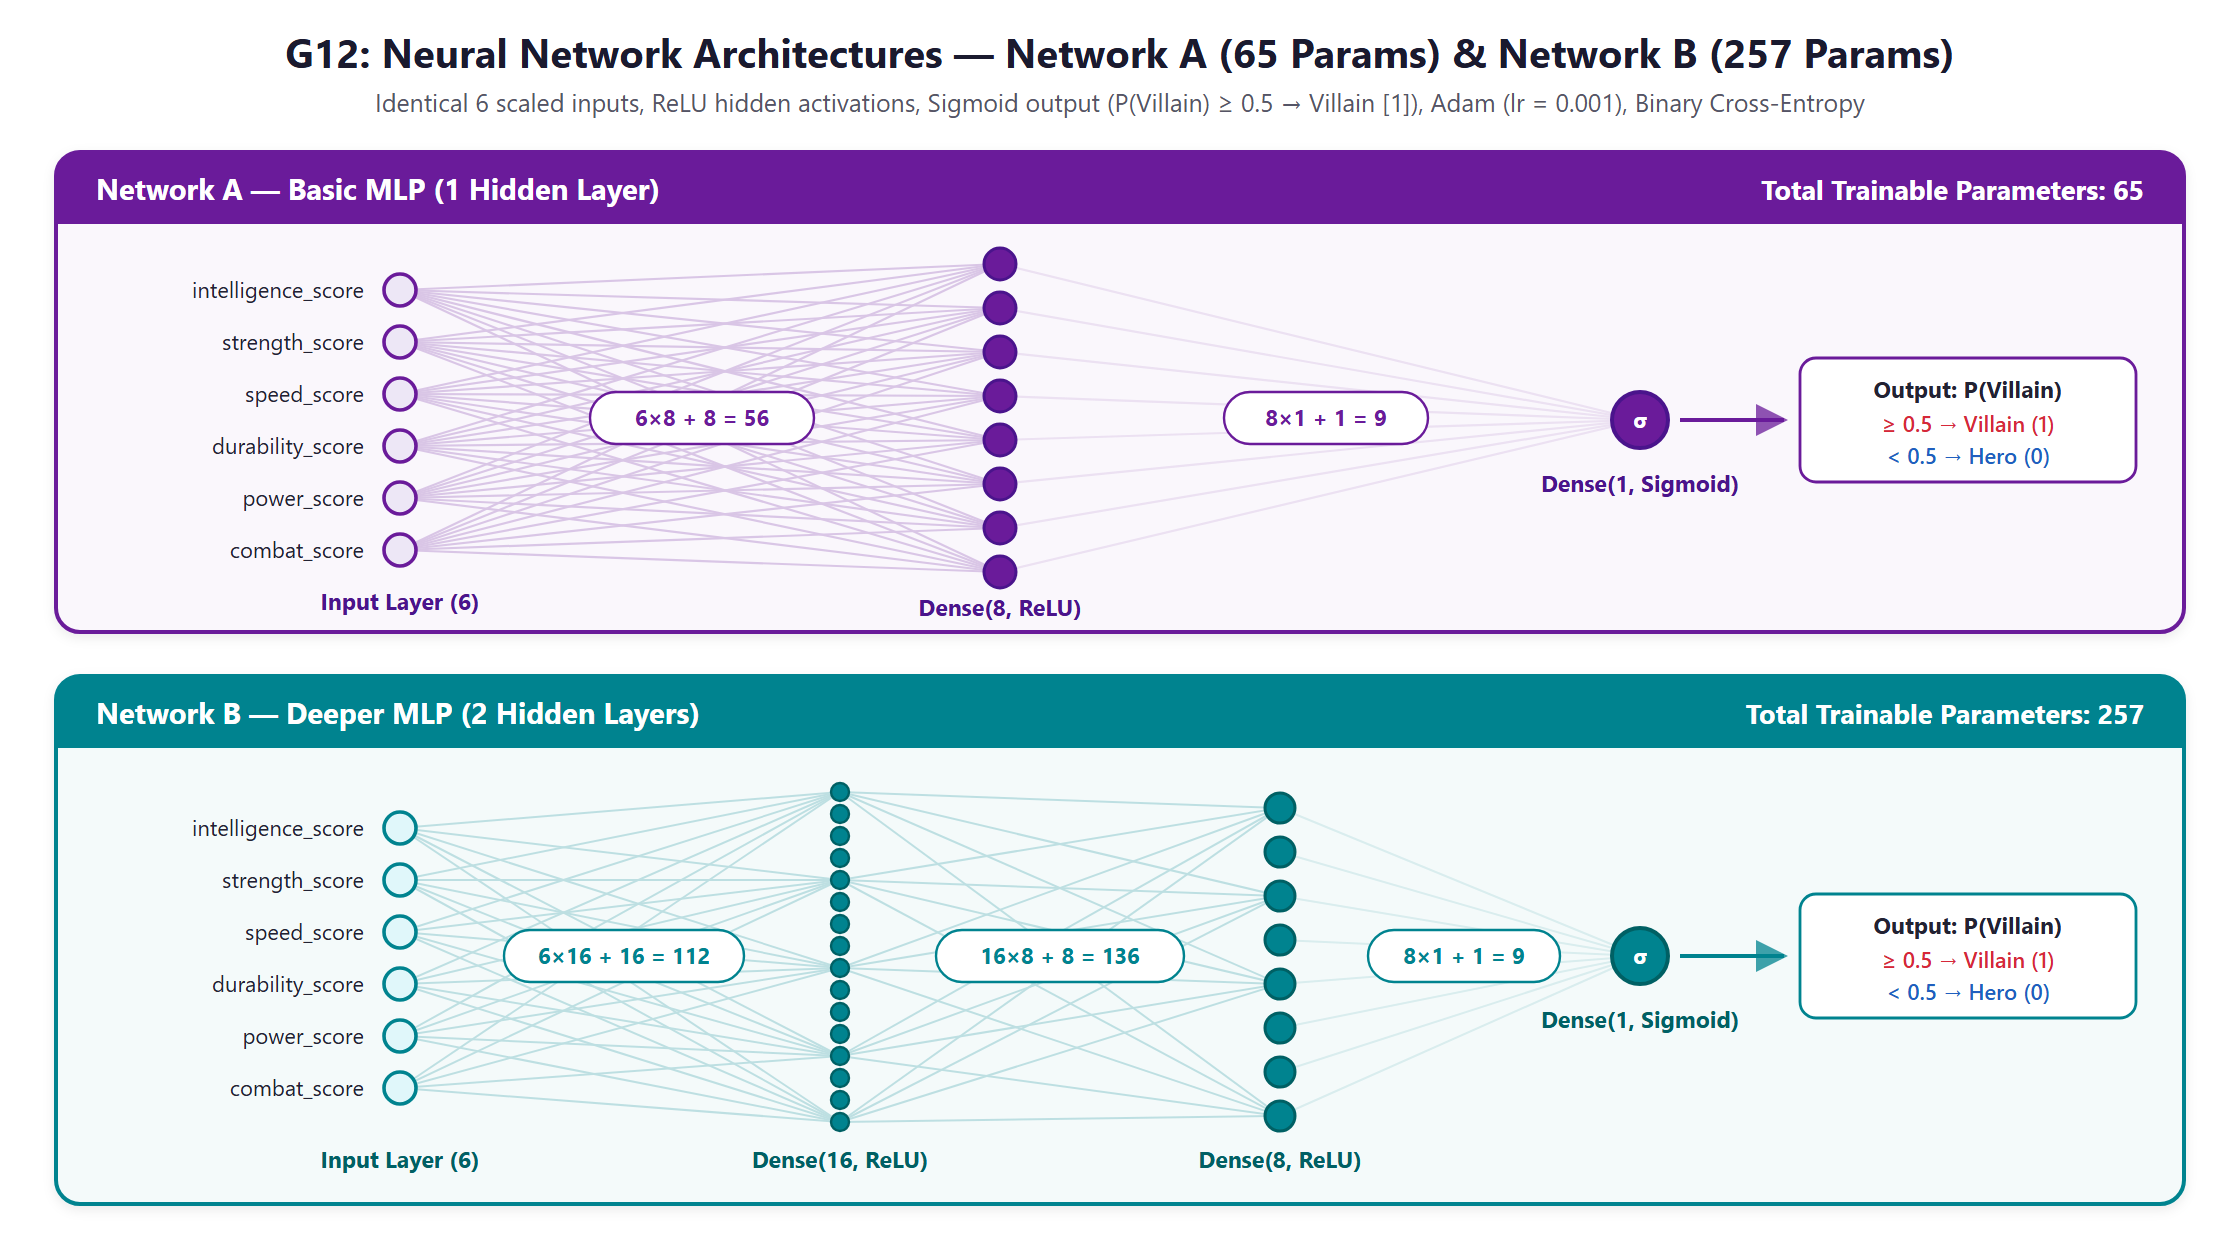

In [21]:
X_nn_fit, X_nn_val, y_nn_fit, y_nn_val = train_test_split(
    X_train_B, y_train_B, test_size=0.2, stratify=y_train_B, random_state=RANDOM_STATE
)

nn_imputer = SimpleImputer(strategy="median")
nn_scaler = StandardScaler()

X_nn_fit_scaled = nn_scaler.fit_transform(nn_imputer.fit_transform(X_nn_fit))
X_nn_val_scaled = nn_scaler.transform(nn_imputer.transform(X_nn_val))
X_nn_test_scaled = nn_scaler.transform(nn_imputer.transform(X_test_B))

print(f"NN 80% fit shape: {X_nn_fit_scaled.shape}, 20% val shape: {X_nn_val_scaled.shape}, test shape: {X_nn_test_scaled.shape}")

display(Markdown("### Graph G12: Architecture Diagrams — Network A & Network B"))
display(IPyImage(filename=str(FIG_DIR / "G12.png"), width=920))

**Graph G12 Caption:** G12 illustrates the locked architectures of Network A (`6 → 8 ReLU → 1 sigmoid`, 65 trainable parameters) and Network B (`6 → 16 ReLU → 8 ReLU → 1 sigmoid`, 257 trainable parameters). Both models ingest the same 6 scaled ability scores and output `P(Villain)` with decision threshold 0.5.

In [22]:
def build_and_train(arch_name, hidden_units):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    layers = [tf.keras.layers.Input(shape=(6,))]
    for u in hidden_units:
        layers.append(tf.keras.layers.Dense(u, activation="relu"))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers, name=arch_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    es = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    )
    hist = model.fit(
        X_nn_fit_scaled, y_nn_fit.values,
        validation_data=(X_nn_val_scaled, y_nn_val.values),
        epochs=200,
        batch_size=32,
        callbacks=[es],
        verbose=0,
    )
    best_epoch = int(np.argmin(hist.history["val_loss"]) + 1)
    return model, hist.history, best_epoch

model_A, hist_A, best_ep_A = build_and_train("Network_A", [8])
model_B, hist_B, best_ep_B = build_and_train("Network_B", [16, 8])

params_A = int(np.sum([np.prod(v.shape) for v in model_A.trainable_variables]))
params_B = int(np.sum([np.prod(v.shape) for v in model_B.trainable_variables]))
assert params_A == 65, f"Expected 65 params, got {params_A}"
assert params_B == 257, f"Expected 257 params, got {params_B}"

t9_df = pd.DataFrame([
    {
        "Network": "Network A",
        "Architecture": "6 -> 8 (ReLU) -> 1 (Sigmoid)",
        "Trainable Params": params_A,
        "Optimizer & LR": "Adam (0.001)",
        "Loss": "binary_crossentropy",
        "Batch / Max Epochs": "32 / 200",
        "EarlyStopping": "val_loss, patience=15",
        "Threshold": 0.5,
        "Epochs Run": len(hist_A["loss"]),
        "Best Epoch": best_ep_A,
        "Best Val Loss": round(float(min(hist_A["val_loss"])), 4),
    },
    {
        "Network": "Network B",
        "Architecture": "6 -> 16 (ReLU) -> 8 (ReLU) -> 1 (Sigmoid)",
        "Trainable Params": params_B,
        "Optimizer & LR": "Adam (0.001)",
        "Loss": "binary_crossentropy",
        "Batch / Max Epochs": "32 / 200",
        "EarlyStopping": "val_loss, patience=15",
        "Threshold": 0.5,
        "Epochs Run": len(hist_B["loss"]),
        "Best Epoch": best_ep_B,
        "Best Val Loss": round(float(min(hist_B["val_loss"])), 4),
    },
])
display(Markdown("### Table T9: Network Settings & Best Epoch"))
display(t9_df)

### Table T9: Network Settings & Best Epoch

,Network,Architecture,Trainable Params,Optimizer & LR,Loss,Batch / Max Epochs,EarlyStopping,Threshold,Epochs Run,Best Epoch,Best Val Loss
0,Network A,6 -> 8 (ReLU) -> 1 (Sigmoid),65,Adam (0.001),binary_crossentropy,32 / 200,"val_loss, patience=15",0.5,166,151,0.6208
1,Network B,6 -> 16 (ReLU) -> 8 (ReLU) -> 1 (Sigmoid),257,Adam (0.001),binary_crossentropy,32 / 200,"val_loss, patience=15",0.5,72,57,0.6332


**Table T9 Caption:** Table T9 records the locked Keras training settings and EarlyStopping results for Network A (65 parameters, best epoch = 151, lowest `val_loss` = 0.6208) and Network B (257 parameters, best epoch = 57, lowest `val_loss` = 0.6332). The deeper Network B stopped 94 epochs earlier and still converged to a slightly higher validation loss than Network A.

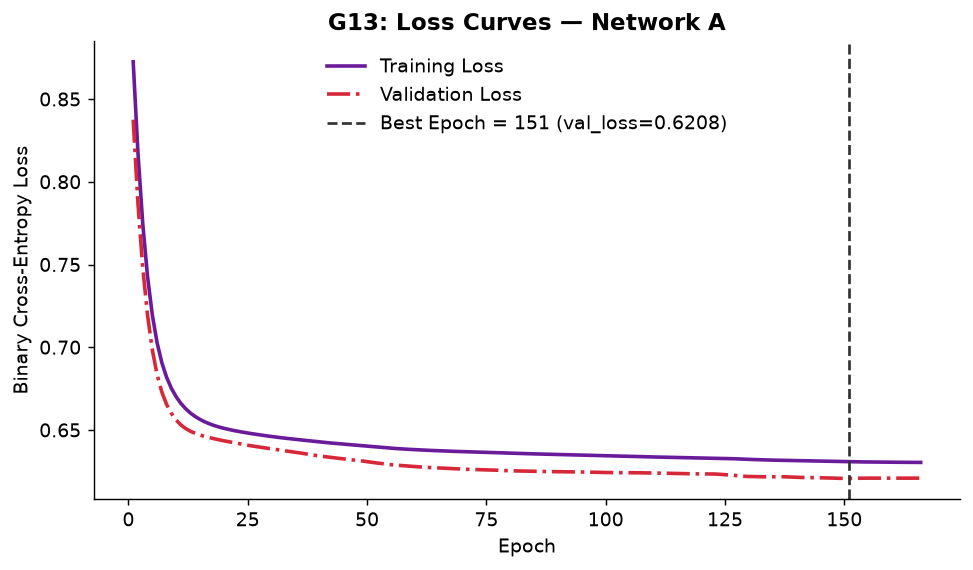

In [23]:
def plot_loss_curve(hist, best_ep, color, title, filename):
    epochs = np.arange(1, len(hist["loss"]) + 1)
    fig, ax = plt.subplots(figsize=(7.6, 4.5))
    ax.plot(epochs, hist["loss"], label="Training Loss", color=color, linewidth=2.0)
    ax.plot(epochs, hist["val_loss"], label="Validation Loss", color="#D62839", linestyle="-.", linewidth=2.0)
    ax.axvline(best_ep, color="#333333", linestyle="--", linewidth=1.5,
               label=f"Best Epoch = {best_ep} (val_loss={hist['val_loss'][best_ep-1]:.4f})")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()

plot_loss_curve(hist_A, best_ep_A, COLORS["Network A"], "G13: Loss Curves — Network A", "G13.png")

**Graph G13 Caption:** G13 shows Network A's training and validation binary cross-entropy loss across 166 epochs, with both curves declining smoothly in tandem until reaching minimum `val_loss` (0.6208) at epoch 151. The parallel downward plateau with no divergence indicates stable optimization without overfitting.

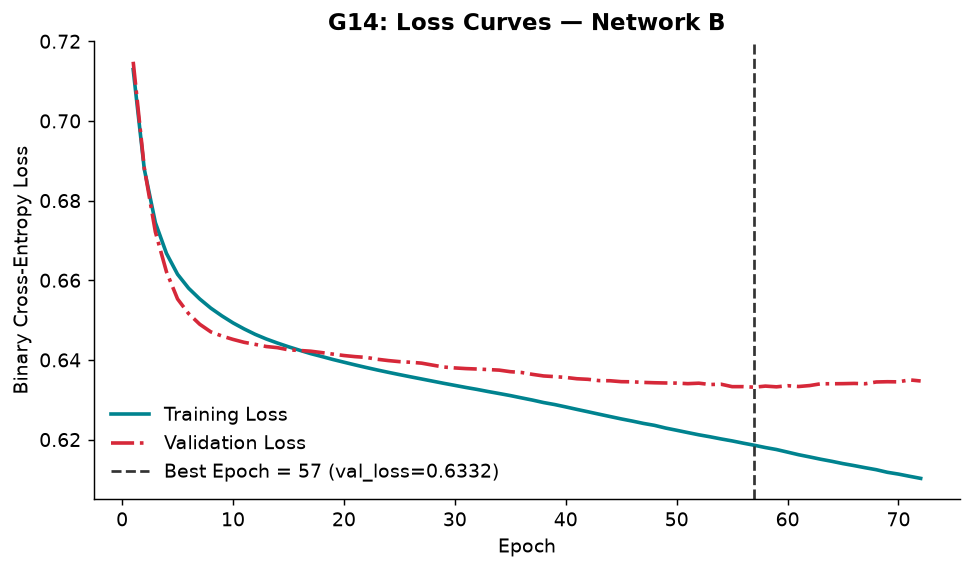

In [24]:
plot_loss_curve(hist_B, best_ep_B, COLORS["Network B"], "G14: Loss Curves — Network B", "G14.png")

**Graph G14 Caption:** G14 plots Network B's loss across 72 epochs: validation loss falls steadily to its minimum (0.6332) at epoch 57, after which training loss keeps falling (0.6186 → 0.6103) while validation loss creeps upward (0.6348 at epoch 72) until EarlyStopping halts training. This late divergence signals mild overfitting from the larger 257-parameter capacity, and `restore_best_weights=True` keeps the epoch-57 weights.

In [25]:
def eval_nn_split(model, X_s, y_true, split_name):
    probs = model.predict(X_s, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    acc = accuracy_score(y_true, preds)
    mf1 = f1_score(y_true, preds, average="macro", zero_division=0)
    ll = "—" if split_name == "Train (80%)" else round(float(log_loss(y_true, probs, labels=[0, 1])), 4)
    return probs, preds, acc, mf1, ll

t10_rows = []
nn_test_preds = {}
nn_test_reports = {}
nn_per_class_rows = []

for net_name, mdl in [("Network A", model_A), ("Network B", model_B)]:
    for s_name, Xs, ys in [
        ("Train (80%)", X_nn_fit_scaled, y_nn_fit.values),
        ("Validation (20%)", X_nn_val_scaled, y_nn_val.values),
        ("Test (test.csv)", X_nn_test_scaled, y_test_B.values),
    ]:
        probs, preds, acc, mf1, ll = eval_nn_split(mdl, Xs, ys, s_name)
        t10_rows.append({
            "Network": net_name,
            "Split": s_name,
            "Accuracy": round(float(acc), 3),
            "Macro-F1": round(float(mf1), 3),
            "Log loss": ll,
        })
        if s_name == "Test (test.csv)":
            nn_test_preds[net_name] = preds
            rep_txt = classification_report(ys, preds, target_names=["Good (Hero)", "Bad (Villain)"], digits=3, zero_division=0)
            rep = classification_report(ys, preds, target_names=["Good (Hero)", "Bad (Villain)"], output_dict=True, zero_division=0)
            nn_test_reports[net_name] = rep
            print(f"=== {net_name} — Test Classification Report ===")
            print(rep_txt)
            nn_per_class_rows.append({
                "Network": net_name,
                "Precision Hero": round(float(rep["Good (Hero)"]["precision"]), 3),
                "Recall Hero": round(float(rep["Good (Hero)"]["recall"]), 3),
                "F1 Hero": round(float(rep["Good (Hero)"]["f1-score"]), 3),
                "Precision Villain": round(float(rep["Bad (Villain)"]["precision"]), 3),
                "Recall Villain": round(float(rep["Bad (Villain)"]["recall"]), 3),
                "F1 Villain": round(float(rep["Bad (Villain)"]["f1-score"]), 3),
            })

t10_df = pd.DataFrame(t10_rows)
t10_per_class_df = pd.DataFrame(nn_per_class_rows)
display(Markdown("### Table T10: Train / Validation / Test Results & Per-Class Test Metrics"))
display(t10_df)
display(Markdown("#### Table T10 (Continued): Per-Class Precision, Recall & F1 on `test.csv`"))
display(t10_per_class_df)

=== Network A — Test Classification Report ===
               precision    recall  f1-score   support

  Good (Hero)      0.621     0.956     0.753       137
Bad (Villain)      0.571     0.091     0.157        88

     accuracy                          0.618       225
    macro avg      0.596     0.524     0.455       225
 weighted avg      0.602     0.618     0.520       225



=== Network B — Test Classification Report ===
               precision    recall  f1-score   support

  Good (Hero)      0.610     0.949     0.743       137
Bad (Villain)      0.417     0.057     0.100        88

     accuracy                          0.600       225
    macro avg      0.513     0.503     0.421       225
 weighted avg      0.535     0.600     0.491       225



### Table T10: Train / Validation / Test Results & Per-Class Test Metrics

,Network,Split,Accuracy,Macro-F1,Log loss
0,Network A,Train (80%),0.653,0.494,—
1,Network A,Validation (20%),0.636,0.460,0.6208
2,Network A,Test (test.csv),0.618,0.455,0.6816
3,Network B,Train (80%),0.661,0.485,—
4,Network B,Validation (20%),0.625,0.422,0.6332
5,Network B,Test (test.csv),0.600,0.421,0.6747


#### Table T10 (Continued): Per-Class Precision, Recall & F1 on `test.csv`

,Network,Precision Hero,Recall Hero,F1 Hero,Precision Villain,Recall Villain,F1 Villain
0,Network A,0.621,0.956,0.753,0.571,0.091,0.157
1,Network B,0.610,0.949,0.743,0.417,0.057,0.100


**Table T10 Caption:** Table T10 reports split-by-split metrics and per-class test results, showing Network A outperforms Network B across validation (Macro-F1 0.460 vs. 0.422; Log loss 0.6208 vs. 0.6332) and test (Macro-F1 0.455 vs. 0.421; Accuracy 0.618 vs. 0.600). Both networks retain high Hero recall (0.956 and 0.949) at the cost of very low Villain recall (0.091 and 0.057).

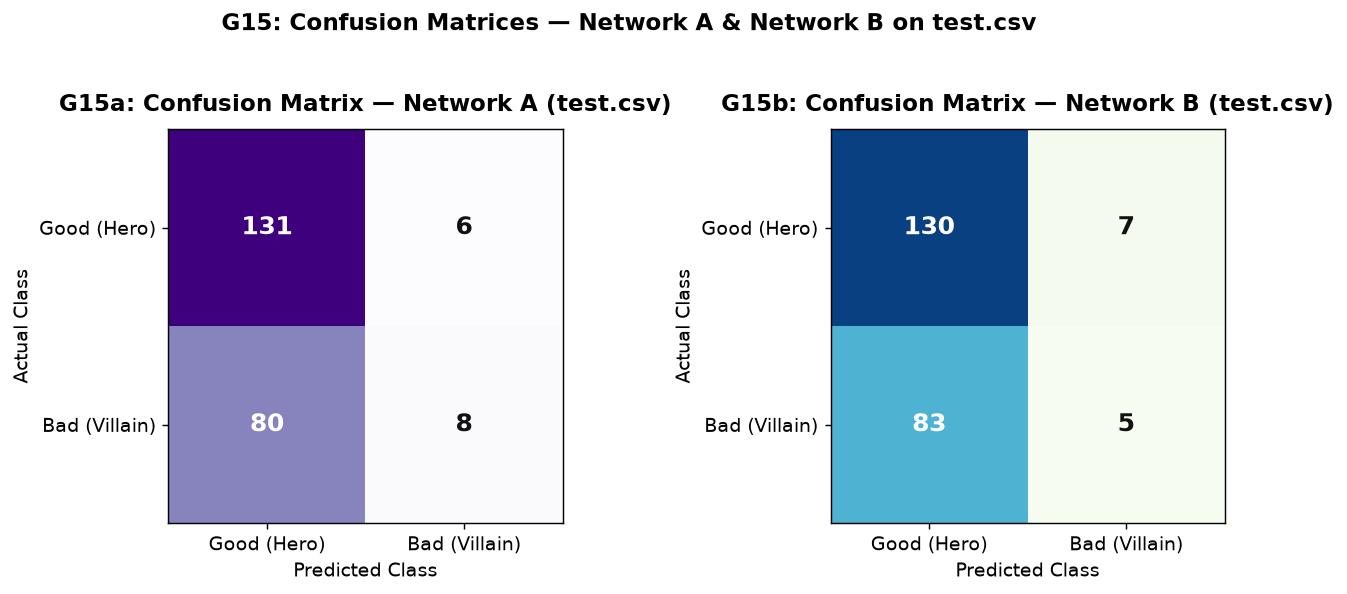

In [26]:
# Graph G15: Confusion Matrices — Network A & Network B
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
plot_cm(axes[0], y_test_B.values, nn_test_preds["Network A"],
        "G15a: Confusion Matrix — Network A (test.csv)", cmap="Purples")
plot_cm(axes[1], y_test_B.values, nn_test_preds["Network B"],
        "G15b: Confusion Matrix — Network B (test.csv)", cmap="GnBu")
fig.suptitle("G15: Confusion Matrices — Network A & Network B on test.csv", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "G15.png", bbox_inches="tight")
plt.show()

**Graph G15 Caption:** G15 displays the `test.csv` confusion matrices for Network A (131 True Heroes, 6 False Villains, 80 missed Villains, 8 True Villains) and Network B (130 True Heroes, 7 False Villains, 83 missed Villains, 5 True Villains). Both MLPs rarely cross the 0.5 probability threshold for Villains, leaving ~91%–94% of Villains misclassified as Heroes.

In [27]:
# Table T11: Final Ranking of All 5 Models on test.csv
all_5 = []
for mname in ["Baseline", "Decision Tree", "KNN"]:
    rep = t1_reports[mname]
    all_5.append({
        "Model": mname,
        "Test accuracy": float(rep["accuracy"]),
        "Test Macro-F1": float(rep["macro avg"]["f1-score"]),
        "Villain recall": float(rep["Bad (Villain)"]["recall"]),
    })
for mname in ["Network A", "Network B"]:
    rep = nn_test_reports[mname]
    all_5.append({
        "Model": mname,
        "Test accuracy": float(rep["accuracy"]),
        "Test Macro-F1": float(rep["macro avg"]["f1-score"]),
        "Villain recall": float(rep["Bad (Villain)"]["recall"]),
    })

baseline_f1 = next(m["Test Macro-F1"] for m in all_5 if m["Model"] == "Baseline")

def rank_models(models_list):
    remaining = list(models_list)
    ranked = []
    while remaining:
        max_f1 = max(m["Test Macro-F1"] for m in remaining)
        contenders = [m for m in remaining if (max_f1 - m["Test Macro-F1"]) < 0.01]
        best = max(contenders, key=lambda m: (m["Villain recall"], m["Test Macro-F1"]))
        ranked.append(best)
        remaining.remove(best)
    return ranked

ranked_5 = rank_models(all_5)
t11_rows = []
for idx, m in enumerate(ranked_5, start=1):
    t11_rows.append({
        "Rank (1–5)": idx,
        "Model": m["Model"],
        "Test accuracy": round(m["Test accuracy"], 3),
        "Test Macro-F1": round(m["Test Macro-F1"], 3),
        "Villain recall": round(m["Villain recall"], 3),
        "Beats baseline?": "yes" if m["Test Macro-F1"] > baseline_f1 else "no",
    })

t11_df = pd.DataFrame(t11_rows)
display(Markdown("### Table T11: Final Ranking of All 5 Models on test.csv"))
display(t11_df)

### Table T11: Final Ranking of All 5 Models on test.csv

,Rank (1–5),Model,Test accuracy,Test Macro-F1,Villain recall,Beats baseline?
0,1,KNN,0.596,0.501,0.205,yes
1,2,Network A,0.618,0.455,0.091,yes
2,3,Network B,0.600,0.421,0.057,yes
3,4,Decision Tree,0.560,0.408,0.068,yes
4,5,Baseline,0.609,0.378,0.000,no


**Table T11 Caption:** Table T11 ranks all five models on `test.csv`: KNN takes 1st place (Test Macro-F1 = 0.501, Villain recall = 0.205), followed by Network A (0.455), Network B (0.421), Decision Tree (0.408), and Baseline (0.378). Every learned model beats the Baseline's Macro-F1, though Network A achieves the highest raw Accuracy (0.618).

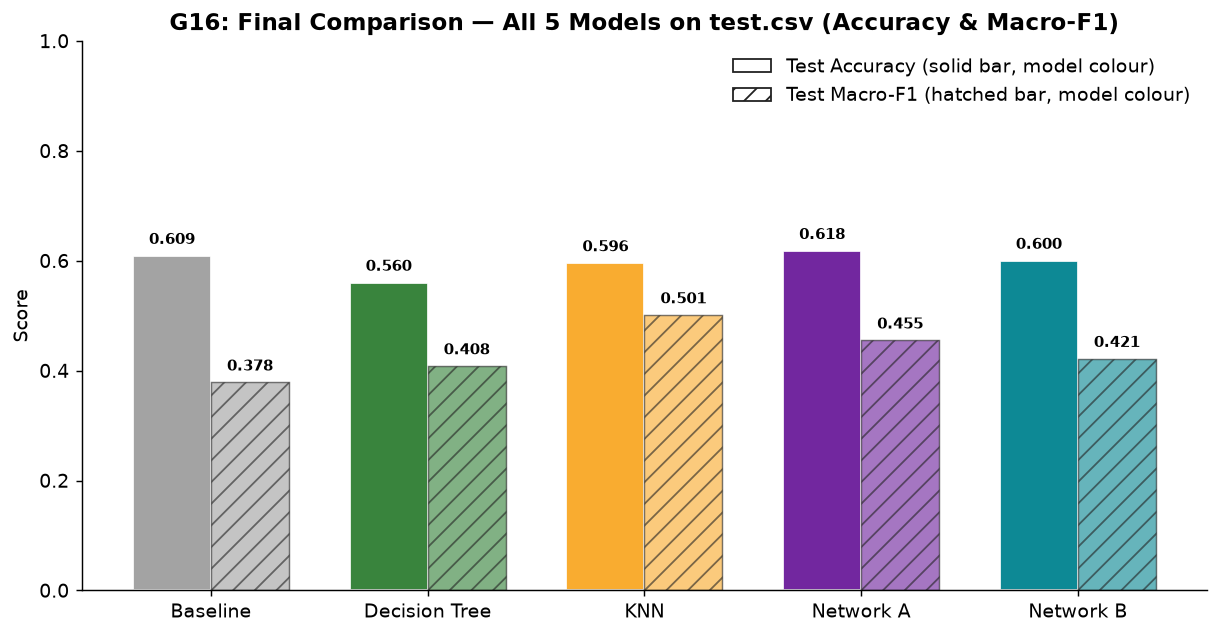

In [28]:
# Graph G16: Final Comparison — All 5 Models
model_order = ["Baseline", "Decision Tree", "KNN", "Network A", "Network B"]
acc_vals = [next(m["Test accuracy"] for m in all_5 if m["Model"] == nm) for nm in model_order]
f1_vals = [next(m["Test Macro-F1"] for m in all_5 if m["Model"] == nm) for nm in model_order]

x = np.arange(len(model_order))
width = 0.36
fig, ax = plt.subplots(figsize=(9.5, 5.0))
bar_colors = [COLORS[nm] for nm in model_order]

b1 = ax.bar(x - width / 2, acc_vals, width, color=bar_colors, alpha=0.95, edgecolor="white", label="Test Accuracy (solid)")
b2 = ax.bar(x + width / 2, f1_vals, width, color=bar_colors, alpha=0.60, hatch="//", edgecolor="#222222", linewidth=0.8, label="Test Macro-F1 (hatched)")

for rect, v in zip(b1, acc_vals):
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.015, f"{v:.3f}",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold")
for rect, v in zip(b2, f1_vals):
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.015, f"{v:.3f}",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_title("G16: Final Comparison — All 5 Models on test.csv (Accuracy & Macro-F1)")
ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
from matplotlib.patches import Patch
metric_handles = [
    Patch(facecolor="white", edgecolor="#222222", label="Test Accuracy (solid bar, model colour)"),
    Patch(facecolor="white", edgecolor="#222222", hatch="//", label="Test Macro-F1 (hatched bar, model colour)"),
]
ax.legend(handles=metric_handles, frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "G16.png", bbox_inches="tight")
plt.show()

**Graph G16 Caption:** G16 compares Test Accuracy and Test Macro-F1 across all five models using their mandated colours. While Accuracy clusters tightly between 0.560 and 0.618 across all models, Macro-F1 clearly separates KNN (0.501) as the best balanced classifier.

### Task 3 Report Answers (Q9–Q12)
- **Q9 (Did Network B beat A by at least `0.01` Macro-F1? Why or why not?):** **No.** Network B achieved **0.421** Test Macro-F1—**0.034 lower** than Network A's **0.455**—so we cannot claim the deeper network improved results (requires `≥ +0.01`). With only 732 training examples and 6 overlapping numeric features, adding a second hidden layer (257 vs. 65 parameters) added variance without extra discriminative power, causing Network B to stop much earlier (epoch 57 vs. 151) with worse Villain recall (0.057 vs. 0.091).
- **Q10 (Do the loss curves show over- or underfitting? Which epoch was best?):** **Network A (`G13`, best epoch = 151, `val_loss = 0.6208`)** shows **no overfitting** (`Train Macro-F1 − Test Macro-F1 = 0.494 − 0.455 = 0.039 ≤ 0.10`, and both loss curves descend smoothly together), though its high ~0.62 loss plateau and low Villain recall reflect **underfitting / weak feature signal**. **Network B (`G14`, best epoch = 57, `val_loss = 0.6332`)** exhibits **mild curve-based overfitting**: its Train–Test Macro-F1 gap is `0.485 − 0.421 = 0.064 ≤ 0.10`, yet after epoch 57 training loss continues falling (`0.6186 → 0.6103`) while validation loss rises slightly (`0.6332 → 0.6348`).
- **Q11 (Did either network beat the Decision Tree and KNN? Give numbers.):** Both networks beat the **Decision Tree** (**0.408** Test Macro-F1): Network A scored **0.455** (`+0.047`) and Network B scored **0.421** (`+0.013`). However, **neither network beat KNN** (**0.501** Test Macro-F1, Villain recall **0.205**), trailing KNN by **0.046** (Network A) and **0.080** (Network B). *Important comparison note:* Decision Tree and KNN trained on **100%** of Clean Set B `train.csv` (916 characters via 5-fold CV), whereas Networks A and B trained on **80%** (732 characters, reserving 184 characters for EarlyStopping validation).
- **Q12 (Name two limitations of this dataset or experiment.):**
  1. **Weak alignment signal in the 6 numeric ability scores alone:** Heroes and Villains share heavily overlapping power profiles (confirmed by weak clustering Silhouette 0.307 and top Test Macro-F1 0.501); alignment depends heavily on narrative biography and backstory columns that were intentionally excluded.
  2. **Class imbalance & zero-coded missing data:** Clean Set B `train.csv` is 64.2% Hero vs. 35.8% Villain, and unweighted models (especially MLPs under binary cross-entropy without class weights or resampling) heavily favour the Hero majority; meanwhile 491 `0` score entries in `train.csv` and 116 in `test.csv` had to be converted to `NaN` (requiring median imputation and dropping 86 + 20 weak rows).

---
## Section 6: Automated Integrity & Pre-Submission Verification

In [29]:
assert list(X_train_B.columns) == FEATURE_COLS and len(X_train_B.columns) == 6
assert list(X_test_B.columns) == FEATURE_COLS and len(X_test_B.columns) == 6
assert list(X_A_raw.columns) == FEATURE_COLS and len(X_A_raw.columns) == 6
assert "overall_score" not in X_train_B.columns and "name" not in X_train_B.columns
assert params_A == 65 and params_B == 257
for i in range(1, 17):
    p = FIG_DIR / f"G{i}.png"
    assert p.exists() and p.stat().st_size > 1000, f"Missing or empty {p}"

print("ALL PROGRAMMATIC CHECKS PASSED:")
print("- Strictly 6 input features verified across Tasks 1, 2, and 3.")
print("- Zero forbidden columns (overall_score, text, has_*, name) used as inputs.")
print("- Neural Network trainable parameter counts verified: Network A = 65, Network B = 257.")
print("- All 16 high-DPI figures G1.png through G16.png verified on disk.")

ALL PROGRAMMATIC CHECKS PASSED:
- Strictly 6 input features verified across Tasks 1, 2, and 3.
- Zero forbidden columns (overall_score, text, has_*, name) used as inputs.
- Neural Network trainable parameter counts verified: Network A = 65, Network B = 257.
- All 16 high-DPI figures G1.png through G16.png verified on disk.
